# Triângulos Quaisquer

**Módulo:** 04 – Geometria Plana

**Pré-requisitos:** [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb) (desigualdade triangular, classificação, "ao maior lado opõe-se o maior ângulo"), [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) (projeção ortogonal e distância de ponto a reta), [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) (base média), [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (mediana, bissetriz, altura, incentro, circuncentro e baricentro), [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (segmentos tangentes congruentes), [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (teorema da bissetriz interna), [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (semelhança e potência de ponto) e [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (o **Teorema de Pitágoras**, a ferramenta de todo este notebook).

**Objetivos de aprendizagem:** ao final você será capaz de...
- Generalizar Pitágoras para triângulos **acutângulos** e **obtusângulos** (com o termo da projeção) e, com isso, **demonstrar** a classificação de um triângulo pelos lados.
- Calcular a **altura** e a **área** de um triângulo qualquer só com os três lados (**fórmula de Herão**) e obter os raios das circunferências **inscrita** e **circunscrita**.
- Calcular o comprimento da **mediana** (teorema da mediana), de **qualquer ceviana** (**teorema de Stewart**) e, daí, o da **bissetriz**.
- Reunir todas as fórmulas numa "calculadora de triângulos" que, dados os três lados, devolve todos os elementos.

**Tempo estimado:** 90 a 105 minutos (é um notebook denso: vale dividir em duas sessões, uma até a seção 2 e outra para as seções 3 a 5)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leandrofreiredealmeida/curso_matematica_python/blob/main/04_geometria_plana/0417a_triangulos_quaisquer.ipynb)

## O terreno sem esquadro

Um terreno triangular tem lados de **13 m**, **14 m** e **15 m**. Você tem só uma **trena**: nada de esquadro, nada de transferidor. Três perguntas:

1. Quanto vale a **área** do terreno?
2. Qual é a **altura** em relação ao lado de 14 m?
3. Onde cai o **pé** dessa altura (a quantos metros de cada ponta do lado de 14 m)?

A tentação é chamar o Teorema de Pitágoras de [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb). Mas ele só vale com um **ângulo reto**, e este terreno não tem nenhum: o maior lado é 15, e $15^2 = 225$, enquanto $13^2 + 14^2 = 365$. Como $225 < 365$, pela classificação de 0416a o triângulo é **acutângulo**. Pitágoras **não resolve direto**.

**Antes de executar:** tente responder às três perguntas com o que você já sabe. Uma dica: a altura divide o terreno em **dois** triângulos retângulos... mas você não sabe onde ela cai. As respostas chegam por partes ao longo do notebook. Rode as células abaixo (a primeira carrega as ferramentas do notebook).

In [1]:
import math
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas de desenho e de medida dos notebooks anteriores (0401a, 0402a, 0407a, 0410a, 0412a, 0415a e 0416a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


def lados(t) -> tuple[float, float, float]:
    """Medidas (a, b, c) dos lados do triângulo t = (A, B, C), na convenção de 0404a: a = BC é oposto a A,
    b = CA é oposto a B e c = AB é oposto a C."""
    A, B, C = t
    return math.dist(B, C), math.dist(C, A), math.dist(A, B)


def angulos(t) -> tuple[float, float, float]:
    """Medidas, em graus, dos ângulos internos (Â, B̂, Ĉ) do triângulo t = (A, B, C)."""
    A, B, C = t
    return medir_angulo(A, B, C), medir_angulo(B, C, A), medir_angulo(C, A, B)


def cruzamento_circunferencias(P, r1: float, Q, r2: float):
    """Um ponto comum às circunferências λ(P, r1) e λ(Q, r2): o que fica à ESQUERDA de quem anda de P para Q
    (0415a). Devolve None se as duas circunferências não se cruzam."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    d = math.dist(P, Q)
    if not abs(r1 - r2) < d < r1 + r2:
        return None
    x = (d**2 + r1**2 - r2**2) / (2 * d)
    y = math.sqrt(r1**2 - x**2)
    u = (Q - P) / d
    return P + x * u + y * np.array([-u[1], u[0]])


def pe_da_altura(vertice, P, Q) -> np.ndarray:
    """Pé da altura traçada de `vertice` até a reta PQ: a projeção ortogonal do vértice sobre essa reta (0407a e
    0410a). Em coordenadas, H = P + ((V − P)·(Q − P) / |Q − P|²)·(Q − P)."""
    V, P, Q = (np.asarray(X, dtype=float) for X in (vertice, P, Q))
    u = Q - P
    return P + np.dot(V - P, u) / np.dot(u, u) * u


def distancia_ponto_reta(X, P, Q) -> float:
    """Distância do ponto X à reta PQ: a medida de X até o pé da perpendicular (0407a)."""
    return math.dist(X, pe_da_altura(X, P, Q))


def baricentro(A, B, C) -> np.ndarray:
    """Baricentro G: a média das coordenadas dos três vértices (0410a)."""
    return (np.asarray(A, dtype=float) + np.asarray(B, dtype=float) + np.asarray(C, dtype=float)) / 3


def incentro(A, B, C) -> np.ndarray:
    """Incentro I: a média dos vértices ponderada pelos lados opostos, I = (a·A + b·B + c·C) / (a + b + c) (0410a)."""
    a, b, c = lados([A, B, C])
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    return (a * A + b * B + c * C) / (a + b + c)


def circuncentro(A, B, C) -> np.ndarray:
    """Circuncentro: o cruzamento das mediatrizes de AB e de BC, as perpendiculares aos lados pelos pontos
    médios (0407a e 0410a)."""
    return cruzamento(ponto_medio(A, B), direcao_de(A, B) + 90, ponto_medio(B, C), direcao_de(B, C) + 90)


def classifica_por_lados(x: float, y: float, z: float) -> str:
    """Classifica o triângulo de lados x, y, z (em qualquer ordem) quanto aos ângulos, só pelos lados:
    'acutângulo', 'retângulo', 'obtusângulo' ou 'não forma triângulo' (0416a)."""
    a, b, c = sorted((x, y, z), reverse=True)  # a é o MAIOR lado
    if c <= 0 or a >= b + c:  # desigualdade triangular (0404a)
        return "não forma triângulo"
    if math.isclose(a**2, b**2 + c**2, rel_tol=1e-9, abs_tol=1e-12):
        return "retângulo"
    return "acutângulo" if a**2 < b**2 + c**2 else "obtusângulo"


# Ferramentas novas deste notebook
# Notação fixa: a = BC, b = CA, c = AB (cada lado na cor do notebook 0416a); h = altura (laranja); nas projeções,
# m = BH (roxo, a cor de c) e n = HC (verde, a cor de b). As cevianas e as circunferências também têm cor fixa.
COR_LADO_A = COR_AVISO  # a: amarelo
COR_LADO_B = COR_DESTAQUE  # b e a projeção n: verde
COR_LADO_C = COR_EXTRA  # c e a projeção m: roxo
COR_ALTURA = "#D08770"  # alturas: laranja
COR_MEDIANA = COR_PONTO  # medianas: azul-claro
COR_BISSETRIZ = COR_ALERTA  # bissetrizes: vermelho
COR_CIRCUNSCRITA = COR_SECUNDARIA  # circunferência circunscrita: azul
COR_INSCRITA = "#8FBCBB"  # circunferência inscrita: verde-água
COR_PARTE_M = "#5E81AC"  # Stewart: a parte BD = m (azul-escuro)
COR_PARTE_N = "#8FBCBB"  # Stewart: a parte DC = n (verde-água)
COR_TRIANGULO = COR_PONTO  # preenchimento dos triângulos


def desenhar_triangulo(ax, A, B, C, valores: bool = True, tamanho: int = 12, preencher: bool = True,
                       rotular_a: bool = True) -> None:
    """Figura padrão do triângulo ABC: a (amarelo), b (verde) e c (roxo), com os nomes dos vértices."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    a, b, c = lados((A, B, C))
    centro, escala = (A + B + C) / 3, max(a, b, c)
    if preencher:
        ax.add_patch(Polygon([A, B, C], closed=True, facecolor=COR_TRIANGULO, alpha=0.12, edgecolor="none",
                             zorder=1))
    for P, Q, cor, nome, valor in ((B, C, COR_LADO_A, "a", a), (C, A, COR_LADO_B, "b", b), (A, B, COR_LADO_C, "c", c)):
        desenhar_segmento(ax, P, Q, cor=cor, largura=3.5)
        if nome != "a" or rotular_a:
            rotular_segmento(ax, P, Q, f"{nome} = {valor:.4g}" if valores else nome, cor=cor,
                             distancia=0.06 * escala, longe_de=centro, tamanho=tamanho)
    for X, nome in ((A, "A"), (B, "B"), (C, "C")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=0.06 * escala, tamanho=tamanho + 1)


def desenhar_projecao(ax, A, B, C, valores: bool = True, faixa: bool = False, tamanho: int = 12) -> list:
    """Triângulo ABC com o lado BC DEITADO no eixo x (B à esquerda de C), a altura AH e as projeções
    m = BH (roxo) e n = HC (verde), com sinal: n < 0 quando H cai depois de C. Com `faixa=True`, desenha
    abaixo de BC as duas faixas a × |n|, cuja área total 2·a·|n| é o que falta (ou sobra) em c² perto de
    a² + b². Devolve pontos que enquadram o desenho (para `preparar_eixo`)."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    a, b, c = lados((A, B, C))
    escala = max(a, b, c)
    H = pe_da_altura(A, B, C)
    n, m = C[0] - H[0], H[0] - B[0]  # com sinal (BC está sobre o eixo x)
    desenhar_triangulo(ax, A, B, C, valores=valores, tamanho=tamanho, rotular_a=False)
    if H[0] > C[0] + 1e-9:
        desenhar_segmento(ax, C, H, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
    if H[0] < B[0] - 1e-9:
        desenhar_segmento(ax, H, B, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
    desenhar_segmento(ax, A, H, cor=COR_ALTURA, largura=2.5, estilo="--")
    if abs(n) > 0.04 * escala and abs(m) > 0.04 * escala:
        desenhar_setor(ax, H, 0 if n > 0 else 90, 90, raio=0.07 * escala, cor=COR_ALTURA)
    lado_h = -1 if n >= 0 else 1  # o rótulo de h vai para o lado oposto ao lado b (que sai de C)
    ax.text(H[0] + 0.015 * escala * lado_h, A[1] / 2, f"h = {A[1]:.4g}" if valores else "h",
            color=COR_ALTURA, fontsize=tamanho, fontweight="bold", ha="left" if lado_h > 0 else "right", va="center")
    desenhar_ponto(ax, H, cor=COR_ALTURA)
    ax.text(H[0], H[1] + 0.05 * escala, "H", color=NORD_TEXTO, fontsize=tamanho + 1, fontweight="bold",
            ha="center", va="bottom", zorder=7)
    # "Réguas" das projeções, em duas alturas para não se sobreporem
    for P, Q, y, cor, nome, valor in ((B, H, -0.07, COR_LADO_C, "m", m), (H, C, -0.14, COR_LADO_B, "n", n)):
        if math.dist(P, Q) < 1e-9:
            continue
        P2, Q2 = P + (0, y * escala), Q + (0, y * escala)
        desenhar_segmento(ax, P2, Q2, cor=cor, largura=3)
        for X in (P2, Q2):
            desenhar_segmento(ax, X + (0, 0.02 * escala), X - (0, 0.02 * escala), cor=cor, largura=1.5)
        ax.text((P2[0] + Q2[0]) / 2, P2[1] - 0.012 * escala, f"{nome} = {valor:.3g}" if valores else nome,
                color=cor, fontsize=tamanho - 1, fontweight="bold", ha="center", va="top")
    y_a = -0.25 * escala
    ax.text((B[0] + C[0]) / 2, y_a, f"a = {a:.4g}" if valores else "a", color=COR_LADO_A, fontsize=tamanho,
            fontweight="bold", ha="center", va="center")
    pontos = [A, B, C, H, np.array([B[0], y_a - 0.03 * escala])]
    if faixa and abs(n) > 1e-9:
        cor = COR_AVISO if n > 0 else COR_ALERTA
        topo = y_a - 0.06 * escala
        for k in range(2):
            ax.add_patch(Rectangle((B[0], topo - (k + 1) * abs(n)), a, abs(n), facecolor=cor, alpha=0.3,
                                   edgecolor=cor, lw=1.5))
            ax.text(B[0] + a / 2, topo - (k + 0.5) * abs(n), f"a·|n| = {a * abs(n):.3g}", color=cor,
                    fontsize=tamanho - 1, fontweight="bold", ha="center", va="center")
        pontos.append(np.array([B[0], topo - 2 * abs(n)]))
    return pontos

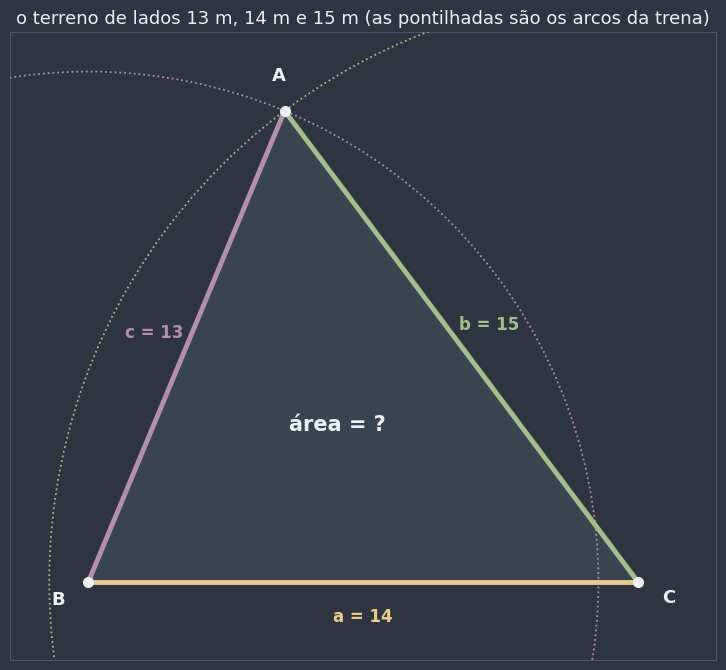

,ângulo entre os lados,terceiro lado SE fosse reto,terceiro lado de verdade,é reto?
0,13 e 14,19.105,15,não
1,13 e 15,19.849,14,não
2,14 e 15,20.518,13,não


maior lado: 15² = 225  ×  13² + 14² = 365  →  acutângulo


In [2]:
# O terreno 13–14–15: B e C nas pontas do lado de 14 m; A fica a 13 m de B e a 15 m de C,
# no cruzamento de duas circunferências (0415a)
B_t, C_t = np.array([0.0, 0.0]), np.array([14.0, 0.0])
A_t = cruzamento_circunferencias(B_t, 13, C_t, 15)

fig, ax = plt.subplots(figsize=(9.5, 6.8))
fig.patch.set_facecolor(NORD_FUNDO)
desenhar_circunferencia(ax, B_t, 13, cor=COR_LADO_C, estilo=":", largura=1.3)
desenhar_circunferencia(ax, C_t, 15, cor=COR_LADO_B, estilo=":", largura=1.3)
desenhar_triangulo(ax, A_t, B_t, C_t)
ax.text(*baricentro(A_t, B_t, C_t), "área = ?", color=NORD_TEXTO, fontsize=15, fontweight="bold", ha="center",
        va="center")
preparar_eixo(ax, [A_t, B_t, C_t], margem=2.0)
ax.set_title("o terreno de lados 13 m, 14 m e 15 m (as pontilhadas são os arcos da trena)", color=NORD_TEXTO,
             fontsize=13)
plt.tight_layout()
plt.show()

# Pitágoras "na marra": se o ângulo entre dois lados fosse reto, quanto mediria o terceiro?
linhas = []
for x, y, z in ((13, 14, 15), (13, 15, 14), (14, 15, 13)):
    linhas.append({"ângulo entre os lados": f"{x} e {y}", "terceiro lado SE fosse reto": f"{math.hypot(x, y):.3f}",
                   "terceiro lado de verdade": z, "é reto?": "sim" if iguais(math.hypot(x, y), z) else "não"})
display(pd.DataFrame(linhas))
print(f"maior lado: 15² = {15**2}  ×  13² + 14² = {13**2 + 14**2}  →  {classifica_por_lados(13, 14, 15)}")

Nenhum dos três ângulos é reto: Pitágoras não se aplica a nenhum par de lados. E repare que o terceiro lado de verdade é sempre **menor** do que seria com o ângulo reto (é o efeito de todos os ângulos serem agudos).

### A dobradiça, de novo

No gancho de [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb), os lados de 3 e 4 ficavam presos num vértice como uma **dobradiça**, e descobrimos que o terceiro lado ao quadrado só empata com $3^2 + 4^2 = 25$ quando o ângulo é reto. Ficou uma pergunta aberta:

> quando o ângulo **não** é 90°, quanto **falta** ou **sobra** para chegar ao quadrado do terceiro lado?

A figura abaixo responde. O lado $a = 4$ fica deitado ($B$ à esquerda, $C$ à direita), o lado $b = 3$ sai de $C$ e o ângulo em $C$ vale 60°, 90° e 120°. A altura $\overline{AH}$ (laranja tracejada) "derruba" o lado $b$ sobre a reta $BC$; o pedaço $n = HC$ (verde) é a **projeção** de $b$ sobre $a$, a mesma ideia de [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) e de 0416a. Embaixo, duas faixas de medidas $a \times |n|$: compare a área delas com a diferença entre $c^2$ e 25.

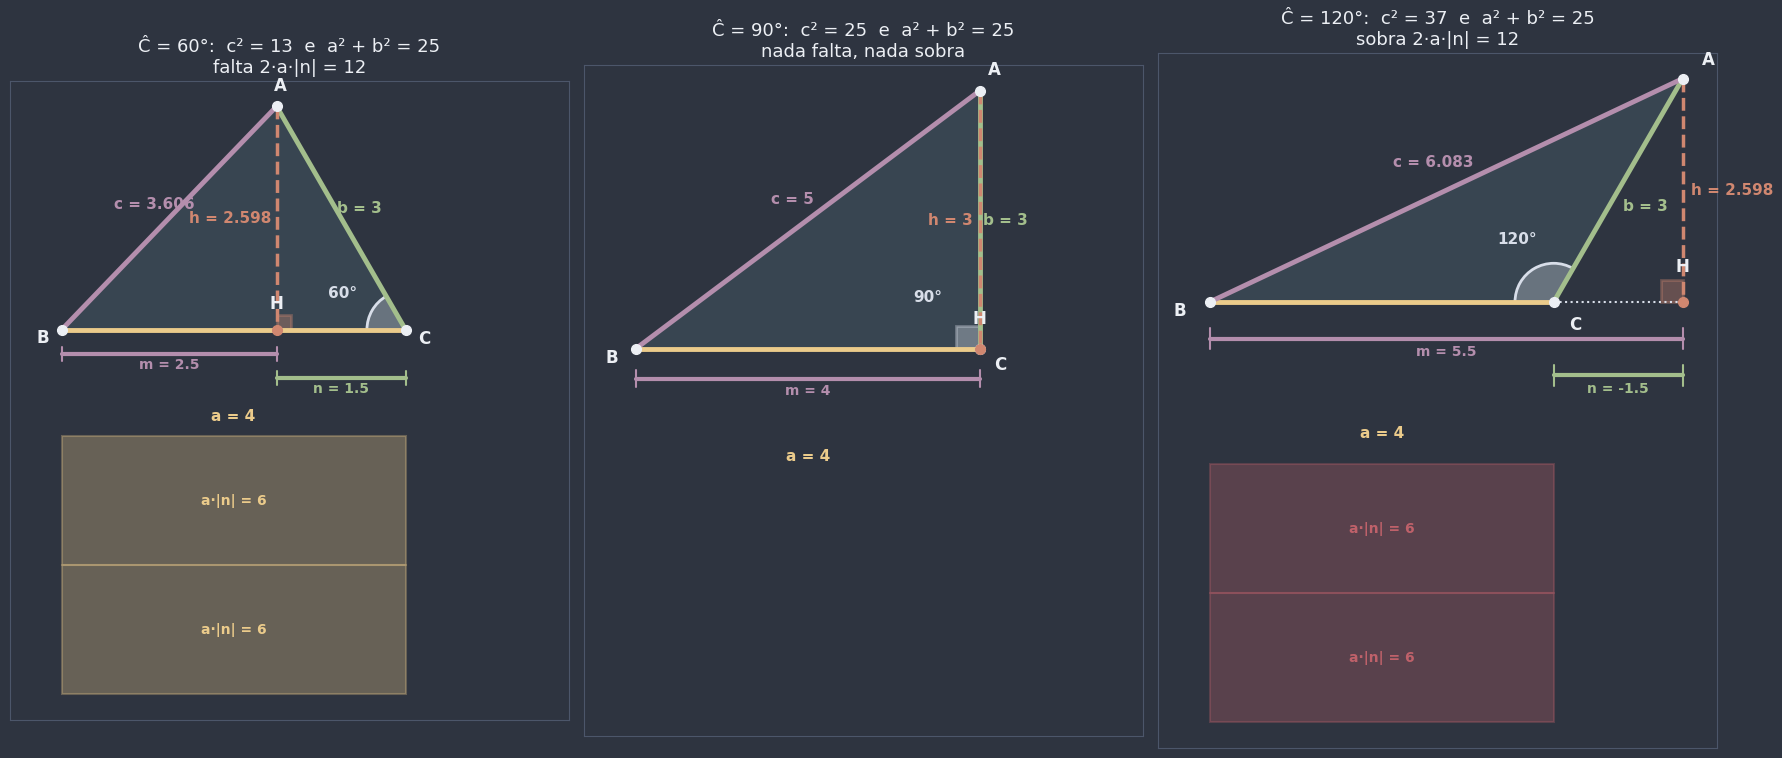

In [3]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 7.6))
fig.patch.set_facecolor(NORD_FUNDO)
a_d, b_d = 4.0, 3.0
B_d, C_d = np.array([0.0, 0.0]), np.array([a_d, 0.0])
for ax, angulo_C in zip(eixos, (60, 90, 120)):
    A_d = C_d + b_d * direcao(180 - angulo_C)  # o lado b sai de C, abrindo o ângulo C
    c_d = math.dist(A_d, B_d)
    n_d = C_d[0] - pe_da_altura(A_d, B_d, C_d)[0]
    pontos = desenhar_projecao(ax, A_d, B_d, C_d, faixa=True, tamanho=11)
    desenhar_arco(ax, C_d, B_d, A_d, raio=0.45, cor=NORD_TEXTO_SEC, rotulo=f"{angulo_C}°", raio_rotulo=0.85)
    preparar_eixo(ax, pontos + [np.array([-0.3, 0]), np.array([5.6, 0]), np.array([0, -4.2])], margem=0.3)
    if abs(n_d) < 1e-9:
        resumo = "nada falta, nada sobra"
    else:
        resumo = f"{'falta' if n_d > 0 else 'sobra'} 2·a·|n| = {2 * a_d * abs(n_d):.3g}"
    ax.set_title(f"Ĉ = {angulo_C}°:  c² = {c_d**2:.3g}  e  a² + b² = 25\n{resumo}", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

Em 60°, $c^2 = 13$: **faltam** 12 para chegar a 25, e as duas faixas amarelas têm área $2 \cdot 4 \cdot 1{,}5 = 12$. Em 120°, $c^2 = 37$: **sobram** 12, e as faixas vermelhas têm área 12 de novo. Em 90°, $n = 0$ e não há faixa nenhuma: é Pitágoras. A conta não é coincidência: em todo triângulo,

$$c^2 = a^2 + b^2 - 2 \cdot a \cdot n,$$

com $n$ positivo quando o ângulo $\hat{C}$ é agudo e negativo quando ele é obtuso. Essa é a ideia da seção 1, e ela vai responder ao terreno.

### O fio condutor deste notebook

Os notebooks anteriores do módulo deixaram várias **promessas** para cá: a classificação pelos lados demonstrada (0404a e 0416a), a base média como ferramenta (0408a), medianas, alturas e bissetrizes calculadas por fórmula (0410a), os segmentos tangentes nas fórmulas (0412a), o comprimento da bissetriz e a razão do incentro (0414a), as cevianas por semelhança e potência de ponto (0415a), e Pitágoras generalizado, Herão e a mediana (0416a). Todas são entregues aqui, e todas saem de **uma única ideia**:

$$\text{Pitágoras (0416a)} \;\longrightarrow\; \text{Pitágoras com projeção (seção 1)} \;\longrightarrow\; \text{altura, área e raios (seção 2)} \;\longrightarrow\; \text{medianas e cevianas (seções 3 e 4)}$$

| Seção | A ideia em uma frase | Demonstrada com... |
|---|---|---|
| 1. Pitágoras além do ângulo reto | $c^2 = a^2 + b^2 \mp 2an$; a altura de qualquer triângulo pelos lados | Pitágoras duas vezes |
| 2. Altura, área e Herão | $S = \sqrt{p(p - a)(p - b)(p - c)}$, $r = \frac{S}{p}$, $R = \frac{abc}{4S}$ | seção 1, segmentos tangentes (0412a), semelhança (0415a) |
| 3. O teorema da mediana | $m_a^2 = \frac{2b^2 + 2c^2 - a^2}{4}$ | seção 1 em dois triângulos |
| 4. Stewart e a bissetriz | $b^2 m + c^2 n = a(d^2 + mn)$; $t_a^2 = bc - mn$ | seção 1, teorema da bissetriz (0414a), potência de ponto (0415a) |
| 5. A calculadora de triângulos | três lados determinam tudo | todas as seções |

**Notação fixa em todo o notebook:** triângulo $ABC$; lados $a = BC$, $b = CA$, $c = AB$ (cada letra minúscula é o lado **oposto** ao vértice de mesma letra); $p = \frac{a + b + c}{2}$ é o **semiperímetro**; $h_a$, $m_a$ e $t_a$ são a altura, a mediana e a bissetriz traçadas de $A$ (e analogamente para $B$ e $C$); $S$ é a área; $r$ e $R$ são os raios das circunferências inscrita e circunscrita. Nas projeções, a convenção de 0416a: $H$ é o pé da altura de $A$, $m = BH$ é a projeção de $c$ e $n = HC$ é a projeção de $b$ sobre o lado $a$.

As cores também são fixas: $a$ amarelo, $b$ e a sua projeção $n$ verdes, $c$ e a sua projeção $m$ roxos, alturas laranja, medianas azul-claras, bissetrizes vermelhas, circunscrita azul e inscrita verde-água.

## 1. Pitágoras além do ângulo reto: ângulos agudos e obtusos

No triângulo $ABC$, trace a altura $\overline{AH}$ relativa ao lado $a$ e chame $h = AH$. O pé $H$ está na **reta** $BC$, mas nem sempre no **segmento** $\overline{BC}$: ele pode cair fora, se um dos ângulos da base for obtuso ([`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)). A projeção de $b$ sobre a reta $BC$ mede $n = HC$.

A altura cria **dois triângulos retângulos**: $AHC$ (catetos $h$ e $n$, hipotenusa $b$) e $AHB$ (catetos $h$ e $BH$, hipotenusa $c$). Pitágoras em cada um:

$$b^2 = h^2 + n^2 \qquad\text{e}\qquad c^2 = h^2 + BH^2.$$

Tudo depende de quanto mede $BH$, e isso depende do ângulo $\hat{C}$:

| Caso | Onde cai $H$ | $BH$ | Pitágoras em $ABH$ | Resultado |
|---|---|---|---|---|
| $\hat{C}$ **agudo** | na semirreta $CB$, a $n$ de $C$ | $\lvert a - n \rvert$ | $c^2 = h^2 + (a - n)^2 = \underbrace{(h^2 + n^2)}_{b^2} + a^2 - 2an$ | $c^2 = a^2 + b^2 - 2an$ |
| $\hat{C}$ **reto** | em $C$ ($n = 0$) | $a$ | $c^2 = h^2 + a^2$, com $h = b$ | $c^2 = a^2 + b^2$ |
| $\hat{C}$ **obtuso** | no prolongamento de $\overline{BC}$, **depois** de $C$ | $a + n$ | $c^2 = h^2 + (a + n)^2 = \underbrace{(h^2 + n^2)}_{b^2} + a^2 + 2an$ | $c^2 = a^2 + b^2 + 2an$ |

(No caso agudo, $H$ pode até cair antes de $B$, se $\hat{B}$ for obtuso: aí $BH = n - a$, mas $(n - a)^2 = (a - n)^2$ e a conta é a mesma.)

📌 **Definição formal (Pitágoras generalizado):** em todo triângulo, o quadrado do lado oposto a um ângulo **agudo** é igual à soma dos quadrados dos outros dois lados **menos** duas vezes o produto de um deles pela projeção do outro sobre ele; se o ângulo é **obtuso**, é **mais**:

$$\hat{C} \text{ agudo: } c^2 = a^2 + b^2 - 2 \cdot a \cdot n \qquad\qquad \hat{C} \text{ obtuso: } c^2 = a^2 + b^2 + 2 \cdot a \cdot n.$$

### Consequência: a classificação pelos lados, demonstrada

Em [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb), a classificação pelos lados foi só **verificada numericamente** (a dobradiça). Agora ela sai em uma linha: como $a > 0$ e $n > 0$ (comprimento),

$$c^2 < a^2 + b^2 \iff \hat{C} \text{ agudo} \qquad c^2 = a^2 + b^2 \iff \hat{C} \text{ reto} \qquad c^2 > a^2 + b^2 \iff \hat{C} \text{ obtuso}.$$

(Os três casos esgotam as possibilidades, por isso valem as setas nos dois sentidos.) E basta olhar o **maior** lado: o maior ângulo é oposto a ele ([`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb)), e o triângulo é obtusângulo, retângulo ou acutângulo conforme o seu maior ângulo. $\blacksquare$

### A altura de um triângulo qualquer, só com os lados

Isolando $n$ na fórmula do caso agudo:

$$n = \frac{a^2 + b^2 - c^2}{2a}.$$

O truque é deixar o **sinal** trabalhar: se der $n > 0$, o ângulo $\hat{C}$ é agudo; se der $n < 0$, ele é obtuso, $H$ cai depois de $C$ e o comprimento $HC$ é $\lvert n \rvert$ (a fórmula do caso obtuso é a mesma com $n$ trocado por $-n$). Com $n$ em mãos, Pitágoras em $AHC$ dá a altura:

$$h_a = \sqrt{b^2 - n^2}.$$

**O terreno, primeira parte:** com $a = 14$, $b = 15$ e $c = 13$,

$$n = \frac{14^2 + 15^2 - 13^2}{2 \cdot 14} = \frac{196 + 225 - 169}{28} = \frac{252}{28} = 9, \qquad h_a = \sqrt{15^2 - 9^2} = \sqrt{144} = 12.$$

A altura relativa ao lado de 14 m mede **12 m**, e o pé dela divide esse lado em $m = 14 - 9 = 5$ m (do lado de $B$) e $n = 9$ m (do lado de $C$). Respondidas as perguntas 2 e 3; a área fica para a seção 2.

📎 **Conexão (Trigonometria):** o número $n$ é o que a Trigonometria chama de $b \cdot \cos \hat{C}$, e a relação $c^2 = a^2 + b^2 - 2ab \cos \hat{C}$ é a **Lei dos Cossenos**, de [`0510a_triangulos_quaisquer.ipynb`](../05_trigonometria/0510a_triangulos_quaisquer.ipynb). Aqui não usamos cosseno nenhum: a dedução acima é exatamente a **prova geométrica** dessa lei.

**No código:** `existe_triangulo` testa a desigualdade triangular **antes de tudo**; `projecao_lado(a, b, c)` devolve $n$ com sinal; `altura_por_lados(a, b, c)` devolve $h_a$; e `triangulo_por_lados(a, b, c)` reconstrói o triângulo em coordenadas com $B = (0, 0)$, $C = (a, 0)$ e $A = (m, h_a)$, em que $m = BH = a - n$. Um `assert` confere que as três distâncias voltam a ser $a$, $b$ e $c$, e a última coluna compara com o $A$ achado pelo cruzamento de duas circunferências (o método do gancho).

In [4]:
def existe_triangulo(a: float, b: float, c: float) -> bool:
    """Desigualdade triangular (0404a): três medidas positivas formam triângulo se cada uma é menor que a soma
    das outras duas."""
    return a > 0 and b > 0 and c > 0 and a < b + c and b < a + c and c < a + b


def projecao_lado(a: float, b: float, c: float) -> float:
    """Projeção n = HC do lado b sobre o lado a, COM SINAL: n = (a² + b² − c²)/(2a). Positiva se o ângulo C é
    agudo, zero se é reto e negativa se é obtuso (nesse caso H cai depois de C e HC = |n|)."""
    return (a**2 + b**2 - c**2) / (2 * a)


def altura_por_lados(a: float, b: float, c: float) -> float:
    """Altura h_a, relativa ao lado a, pelos três lados: h_a = √(b² − n²) (Pitágoras no triângulo AHC)."""
    if not existe_triangulo(a, b, c):
        raise ValueError(f"as medidas {a}, {b}, {c} não formam triângulo (desigualdade triangular)")
    n = projecao_lado(a, b, c)
    return math.sqrt(b**2 - n**2)


def triangulo_por_lados(a: float, b: float, c: float):
    """Triângulo (A, B, C) com BC = a deitado no eixo x: B = (0, 0), C = (a, 0) e A = (m, h_a), com m = a − n.
    Devolve None se as medidas não formam triângulo."""
    if not existe_triangulo(a, b, c):
        return None
    n = projecao_lado(a, b, c)
    return np.array([a - n, altura_por_lados(a, b, c)]), np.array([0.0, 0.0]), np.array([float(a), 0.0])


linhas = []
for a, b, c in ((14, 15, 13), (5, 4, 3), (4, 5, 7), (6, 6, 6), (2, 3, 7)):
    t = triangulo_por_lados(a, b, c)
    if t is None:
        linhas.append({"a, b, c": f"{a}, {b}, {c}", "classificação": classifica_por_lados(a, b, c)})
        continue
    A, B, C = t
    assert all(iguais(x, y) for x, y in zip(lados(t), (a, b, c)))  # as três distâncias voltam a ser a, b, c
    n = projecao_lado(a, b, c)
    linhas.append({
        "a, b, c": f"{a}, {b}, {c}",
        "classificação": classifica_por_lados(a, b, c),
        "n = HC (com sinal)": f"{n:.4g}",
        "Ĉ medido": f"{medir_angulo(C, A, B):.2f}°",
        "m = BH": f"{a - n:.4g}",
        "h_a": f"{altura_por_lados(a, b, c):.4g}",
        "A = (m, h_a)": f"({A[0]:.4g}, {A[1]:.4g})",
        "igual ao das circunferências?": "✅" if np.allclose(A, cruzamento_circunferencias(B, c, C, b)) else "❌",
    })
display(pd.DataFrame(linhas).fillna("—"))

# A relação c² = a² + b² − 2·a·n vale nos três casos, com n com sinal
for a, b, c in ((14, 15, 13), (5, 4, 3), (4, 5, 7)):
    n = projecao_lado(a, b, c)
    print(f"a, b, c = {a}, {b}, {c}:  c² = {c**2}   a² + b² − 2·a·n = {a**2} + {b**2} − 2·{a}·({n:g}) = "
          f"{a**2 + b**2 - 2 * a * n:g}")

,"a, b, c",classificação,n = HC (com sinal),Ĉ medido,m = BH,h_a,"A = (m, h_a)",igual ao das circunferências?
0,"14, 15, 13",acutângulo,9,53.13°,5,12,"(5, 12)",✅
1,"5, 4, 3",retângulo,3.2,36.87°,1.8,2.4,"(1.8, 2.4)",✅
2,"4, 5, 7",obtusângulo,-1,101.54°,5,4.899,"(5, 4.899)",✅
3,"6, 6, 6",acutângulo,3,60.00°,3,5.196,"(3, 5.196)",✅
4,"2, 3, 7",não forma triângulo,—,—,—,—,—,—


a, b, c = 14, 15, 13:  c² = 169   a² + b² − 2·a·n = 196 + 225 − 2·14·(9) = 169
a, b, c = 5, 4, 3:  c² = 9   a² + b² − 2·a·n = 25 + 16 − 2·5·(3.2) = 9
a, b, c = 4, 5, 7:  c² = 49   a² + b² − 2·a·n = 16 + 25 − 2·4·(-1) = 49


O sinal de $n$ conta a história: no 13–14–15, $n = 9 > 0$ e $\hat{C} \approx 53{,}13°$ é agudo; no 3–4–5 (escrito como $a = 5$, $b = 4$, $c = 3$), $n = 3{,}2$ e o ângulo reto está em $A$, não em $C$; no 4–5–7, $n = -1$: $\hat{C} \approx 101{,}5°$ é obtuso e $H$ cai **fora** do lado, 1 unidade depois de $C$. O trio 2–3–7 não passa da desigualdade triangular, e as funções nem tentam (`altura_por_lados` avisaria com um `ValueError`).

A representação gráfica dos dois casos: à esquerda, o terreno (agudo, $H$ entre $B$ e $C$); à direita, o 4–5–7 (obtuso em $C$, com o prolongamento de $\overline{BC}$ pontilhado até $H$). Em cada um, os dois triângulos retângulos da demonstração estão sombreados: $AHC$ em verde e $AHB$ em roxo.

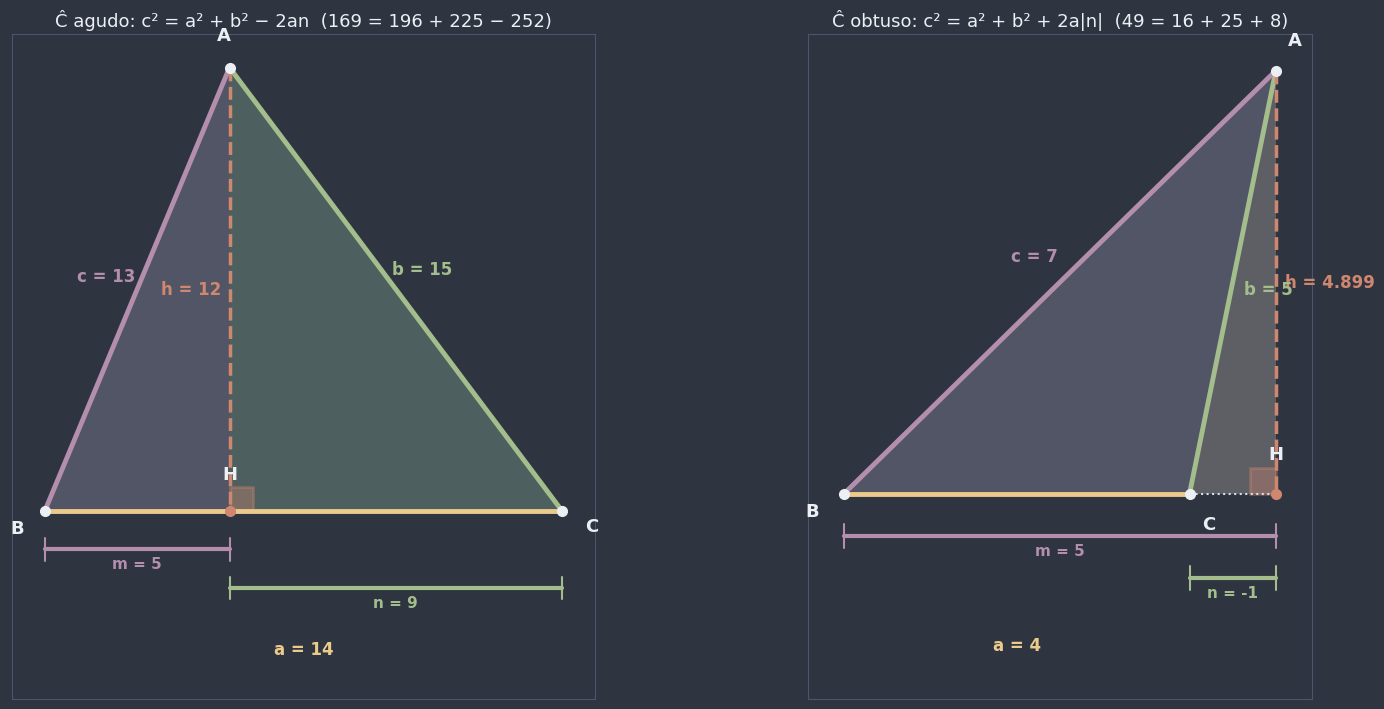

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(17, 7.2), gridspec_kw={"width_ratios": [1.45, 1]})
fig.patch.set_facecolor(NORD_FUNDO)
for ax, (a, b, c), titulo in ((eixos[0], (14, 15, 13), "Ĉ agudo: c² = a² + b² − 2an  (169 = 196 + 225 − 252)"),
                              (eixos[1], (4, 5, 7), "Ĉ obtuso: c² = a² + b² + 2a|n|  (49 = 16 + 25 + 8)")):
    A, B, C = triangulo_por_lados(a, b, c)
    H = pe_da_altura(A, B, C)
    ax.add_patch(Polygon([A, H, C], closed=True, facecolor=COR_LADO_B, alpha=0.22, edgecolor="none", zorder=1))
    ax.add_patch(Polygon([A, H, B], closed=True, facecolor=COR_LADO_C, alpha=0.22, edgecolor="none", zorder=1))
    pontos = desenhar_projecao(ax, A, B, C)
    preparar_eixo(ax, pontos, margem=0.06 * max(a, b, c))
    ax.set_title(titulo, color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

No caso obtuso, os dois triângulos retângulos se **sobrepõem**: $AHB$ (roxo) contém $AHC$ (verde). É por isso que ali $BH = a + \lvert n \rvert$, e o sinal troca.

🕹️ **Widget interativo — a dobradiça completa:** o lado $a = 6$ fica deitado e o lado $b = 4$ sai de $C$; o slider abre o ângulo $\hat{C}$ de 30° a 150°. O triângulo, a altura, o pé $H$ e a projeção $n$ são recalculados em tempo real, e as faixas $a \times \lvert n \rvert$ aparecem embaixo: **amarelas** quando faltam (ângulo agudo) e **vermelhas** quando sobram (ângulo obtuso). Observe o ponto $H$ **trocar de lado** de $C$ ao passar por 90°, e o sinal de $n$ trocar junto. O painel da direita confere a fórmula a cada posição.

In [6]:
def explorar_projecao(angulo_C: float) -> None:
    a, b = 6.0, 4.0
    B, C = np.array([0.0, 0.0]), np.array([a, 0.0])
    A = C + b * direcao(180 - angulo_C)  # o lado b sai de C abrindo o ângulo C
    c = math.dist(A, B)
    n = projecao_lado(a, b, c)
    classe = classifica_por_lados(a, b, c)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 7.2), gridspec_kw={"width_ratios": [1.25, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_projecao(ax, A, B, C, faixa=True, tamanho=11)
    desenhar_arco(ax, C, B, A, raio=0.55, cor=NORD_TEXTO_SEC, rotulo=f"{angulo_C:.0f}°", raio_rotulo=1.0)
    preparar_eixo(ax, [(-0.4, 4.4), (10.2, -8.7)], margem=0.2)
    ax.set_title(f"Ĉ = {angulo_C:.0f}°  →  triângulo {classe}", color=NORD_TEXTO, fontsize=13)

    if math.isclose(n, 0, abs_tol=1e-9):
        posicao_H, sinal = "H coincide com C (ângulo reto)", "c² = a² + b²  (Pitágoras)"
    elif n > 0:
        posicao_H, sinal = "H fica ANTES de C, do lado de B", "c² = a² + b² − 2·a·n  (falta)"
    else:
        posicao_H, sinal = "H fica DEPOIS de C, fora do lado", "c² = a² + b² + 2·a·|n|  (sobra)"
    itens = [
        (f"n = (a² + b² − c²)/(2a) = {n:.3f}", True),
        (f"n medido (de H até C) = {C[0] - pe_da_altura(A, B, C)[0]:.3f}", iguais(n, C[0] - pe_da_altura(A, B, C)[0])),
        (posicao_H, True),
        (sinal, True),
        (f"c² = {c**2:.3f}   a² + b² − 2an = {a**2 + b**2 - 2 * a * n:.3f}", iguais(c**2, a**2 + b**2 - 2 * a * n)),
        (f"faixas: 2·a·|n| = {2 * a * abs(n):.3f} = |c² − (a² + b²)|", iguais(2 * a * abs(n), abs(c**2 - 52))),
        (f"h_a = √(b² − n²) = {altura_por_lados(a, b, c):.3f} = altura medida", iguais(altura_por_lados(a, b, c), A[1])),
    ]
    escrever_checklist(ax_lista, itens, f"a = 6, b = 4, c = {c:.3f}")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_projecao,
    angulo_C=widgets.IntSlider(value=120, min=30, max=150, step=1, description="ângulo Ĉ:"),
);

interactive(children=(IntSlider(value=120, description='ângulo Ĉ:', max=150, min=30), Output()), _dom_classes=…

🎯 **Aplicação prática — telhados e estruturas:** numa tesoura de telhado, os caibros nem sempre formam ângulo reto com a linha. Se uma viga de 6 m e outra de 4 m saem do mesmo ponto com abertura obtusa, a peça que fecha o triângulo mede $\sqrt{6^2 + 4^2 + 2 \cdot 6 \cdot \lvert n \rvert}$: basta medir, com a trena, quanto a projeção de uma viga "passa" da outra. E o teste inverso serve para conferir uma estrutura pronta: medindo os três lados, a comparação de $c^2$ com $a^2 + b^2$ diz se o ângulo ficou agudo, reto ou obtuso, sem transferidor.

⚠️ **Erro comum: usar $a^2 = b^2 + c^2$ "porque o triângulo parece retângulo".** Pitágoras **só** vale com ângulo reto; nos outros casos entra o termo $\mp 2an$. No terreno 13–14–15, "Pitágoras na marra" daria um terceiro lado de 19,1 ou 20,5, longe dos valores reais.

⚠️ **Erro comum: projetar o lado errado.** Na fórmula $c^2 = a^2 + b^2 - 2an$, o $n$ é a projeção de $b$ **sobre** $a$ (os dois lados que formam o ângulo $\hat{C}$), e o lado isolado, $c$, é o **oposto** a $\hat{C}$. Desenhe sempre a altura antes de escrever a fórmula; e, se trocar o papel dos lados, troque a projeção também: $c^2 = a^2 + b^2 - 2 \cdot b \cdot n'$, com $n'$ a projeção de $a$ sobre $b$.

📖 **Leitura complementar:** [Lei dos cossenos](https://pt.wikipedia.org/wiki/Lei_dos_cossenos) (Wikipédia), a generalização de Pitágoras que esta seção provou geometricamente. O verbete usa trigonometria, que você vê no módulo 05.

**Pergunta de checagem:** os lados de um triângulo são 4, 5 e 7. Ele é acutângulo, retângulo ou obtusângulo? Qual é a projeção do lado 5 sobre o lado 4, e onde cai o pé da altura?

**Pergunta de checagem:** no widget, para qual ângulo $\hat{C}$ o pé $H$ coincide com $C$? E o que acontece com $h_a$ quando o ângulo passa de 90°: ele continua sendo $\sqrt{b^2 - n^2}$?

## 2. Altura, área e a fórmula de Herão; raios inscrito e circunscrito

### Área pela altura

A área de um triângulo é **metade de base × altura**:

$$S = \frac{a \cdot h_a}{2} = \frac{b \cdot h_b}{2} = \frac{c \cdot h_c}{2}.$$

Você conhece essa fórmula do ensino fundamental; a justificativa dela por equivalência de figuras é tema de 📌 Equivalência Plana. Com a seção 1, já dá para responder à primeira pergunta do terreno: $S = \frac{14 \cdot 12}{2} = 84$ m². Mas dá para fazer melhor: uma fórmula que vai **direto dos lados para a área**.

### A fórmula de Herão

Com o semiperímetro $p = \frac{a + b + c}{2}$:

$$S = \sqrt{p \cdot (p - a) \cdot (p - b) \cdot (p - c)}.$$

*Demonstração.* Da seção 1, $n = \frac{a^2 + b^2 - c^2}{2a}$ e $h_a^2 = b^2 - n^2$. Multiplicando por $4a^2$ e usando **diferença de quadrados** duas vezes:

| Passo | Expressão | Por quê |
|---|---|---|
| 1 | $4a^2 h_a^2 = 4a^2b^2 - (a^2 + b^2 - c^2)^2$ | $4a^2 n^2 = (a^2 + b^2 - c^2)^2$ |
| 2 | $= \left[2ab - (a^2 + b^2 - c^2)\right] \cdot \left[2ab + (a^2 + b^2 - c^2)\right]$ | $X^2 - Y^2 = (X - Y)(X + Y)$ |
| 3 | $= \left[c^2 - (a - b)^2\right] \cdot \left[(a + b)^2 - c^2\right]$ | quadrados perfeitos |
| 4 | $= (c - a + b)(c + a - b)(a + b - c)(a + b + c)$ | diferença de quadrados de novo |
| 5 | $= 2(p - a) \cdot 2(p - b) \cdot 2(p - c) \cdot 2p = 16 \cdot p(p - a)(p - b)(p - c)$ | $a + b + c = 2p$, $-a + b + c = 2(p - a)$, ... |

Como $S = \frac{a \cdot h_a}{2}$, temos $16 S^2 = 4a^2h_a^2 = 16 \cdot p(p - a)(p - b)(p - c)$, e a fórmula sai tirando a raiz. $\blacksquare$

**O terreno, segunda parte:** $p = \frac{13 + 14 + 15}{2} = 21$ e

$$S = \sqrt{21 \cdot 7 \cdot 6 \cdot 8} = \sqrt{7056} = 84 \text{ m}^2,$$

o mesmo valor da base × altura, agora **sem** calcular altura nenhuma. As três perguntas do gancho estão respondidas.

💡 **Dica: Herão "sabe" se o triângulo existe.** O radicando $p(p - a)(p - b)(p - c)$ só é positivo quando os **quatro** fatores são positivos (no máximo um deles pode ser negativo, porque a soma de dois deles, como $(p - a) + (p - b) = c$, é sempre positiva). E $p > a$, $p > b$, $p > c$ é **exatamente** a desigualdade triangular de [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb): $p > a \iff b + c > a$. Quando $a = b + c$ (o triângulo "achatado"), o fator $p - a$ é zero e a área é zero.

### Os segmentos tangentes: de onde vêm $p - a$, $p - b$ e $p - c$

Cumprindo a promessa de [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb): a circunferência inscrita toca os três lados, e os dois segmentos tangentes traçados de um mesmo vértice são **congruentes**. Chame de $x$, $y$ e $z$ os segmentos tangentes que saem de $A$, $B$ e $C$. Cada lado é a soma de dois deles:

$$x + y = c, \qquad y + z = a, \qquad x + z = b.$$

Somando as três: $2(x + y + z) = a + b + c$, isto é, $x + y + z = p$. Subtraindo cada equação dessa soma:

$$x = p - a, \qquad y = p - b, \qquad z = p - c.$$

No terreno: 7 (de $A$), 6 (de $B$) e 8 (de $C$). Os fatores de Herão **são** os segmentos tangentes!

### Os raios das circunferências inscrita e circunscrita

**Inscrita.** Ligando o incentro $I$ aos três vértices, o triângulo se divide em três triângulos $IBC$, $ICA$ e $IAB$, cada um com altura $r$ (o raio é perpendicular ao lado no ponto de tangência, 0412a):

$$S = \frac{a \cdot r}{2} + \frac{b \cdot r}{2} + \frac{c \cdot r}{2} = \frac{(a + b + c) \cdot r}{2} = p \cdot r \qquad\Longrightarrow\qquad r = \frac{S}{p}.$$

Confira com 0416a: no triângulo retângulo 3–4–5, $S = 6$ e $p = 6$, então $r = 1 = \frac{3 + 4 - 5}{2}$ ✓.

**Circunscrita.** $R = \frac{a \cdot b \cdot c}{4S}$. *Demonstração por semelhança* ([`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)): trace o diâmetro $\overline{AD}$ da circunferência circunscrita (figura com $\hat{B}$ agudo; o caso obtuso é análogo).

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $A\hat{H}B = 90°$ | $\overline{AH}$ é a altura |
| 2 | $A\hat{C}D = 90°$ | $\hat{C}$ enxerga o diâmetro $\overline{AD}$ ([`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)) |
| 3 | $A\hat{B}C = A\hat{D}C$ | ângulos inscritos que enxergam o mesmo arco $\overset{\frown}{AC}$ (0413a) |
| 4 | $\triangle ABH \sim \triangle ADC$ | critério **AA** (passos 1, 2 e 3) |
| 5 | $\dfrac{AB}{AD} = \dfrac{AH}{AC}$, isto é, $\dfrac{c}{2R} = \dfrac{h_a}{b}$ | hipotenusas e lados opostos aos ângulos iguais |
| 6 | $2R \cdot h_a = b \cdot c$, logo $R = \dfrac{bc}{2h_a} = \dfrac{abc}{2a h_a} = \dfrac{abc}{4S}$ | $a \cdot h_a = 2S$ |

No terreno: $r = \frac{84}{21} = 4$ m e $R = \frac{13 \cdot 14 \cdot 15}{4 \cdot 84} = \frac{2730}{336} = 8{,}125$ m.

📌 **Definição formal (área e raios pelos lados):** num triângulo de lados $a$, $b$, $c$ e semiperímetro $p = \frac{a + b + c}{2}$,

$$S = \sqrt{p(p - a)(p - b)(p - c)} \qquad r = \frac{S}{p} \qquad R = \frac{abc}{4S} \qquad \text{segmentos tangentes: } p - a,\ p - b,\ p - c.$$

🕵️ **Curiosidade histórica:** a fórmula leva o nome de **Herão de Alexandria** (século I d.C.), que a demonstra na obra *Métrica*, um manual de medições. Segundo o historiador Thomas Heath, **Arquimedes** já a conheceria uns dois séculos antes, e como a *Métrica* reúne conhecimentos mais antigos, a origem exata é incerta. Uma pergunta para pensar: por que uma fórmula de **área** só precisa dos **lados**? Porque três lados **determinam** o triângulo: é o caso **LLL** de [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb). Dois triângulos com os mesmos lados são congruentes, então têm a mesma área, os mesmos ângulos, as mesmas alturas... tudo é função dos três lados.

**No código:** `semiperimetro`, `area_herao` (que levanta um `ValueError` com mensagem clara se o triângulo não existe), `segmentos_tangentes`, `raio_inscrito` e `raio_circunscrito`. A célula confere o terreno e depois sorteia 2000 triângulos **por coordenadas** e compara: a área de Herão com base × altura (a altura medida por `distancia_ponto_reta`), $R$ com a distância do circuncentro (cruzamento das mediatrizes, 0410a) a um vértice, e $r$ com a distância do incentro a um lado.

In [7]:
def semiperimetro(a: float, b: float, c: float) -> float:
    """Semiperímetro p = (a + b + c)/2."""
    return (a + b + c) / 2


def area_herao(a: float, b: float, c: float) -> float:
    """Área do triângulo de lados a, b, c pela fórmula de Herão: S = √(p(p − a)(p − b)(p − c))."""
    if not existe_triangulo(a, b, c):
        raise ValueError(f"as medidas {a}, {b}, {c} não formam triângulo (desigualdade triangular)")
    p = semiperimetro(a, b, c)
    return math.sqrt(p * (p - a) * (p - b) * (p - c))


def segmentos_tangentes(a: float, b: float, c: float) -> tuple[float, float, float]:
    """Segmentos tangentes da circunferência inscrita traçados de A, B e C: (p − a, p − b, p − c)."""
    p = semiperimetro(a, b, c)
    return p - a, p - b, p - c


def raio_inscrito(a: float, b: float, c: float) -> float:
    """Raio da circunferência inscrita: r = S/p."""
    return area_herao(a, b, c) / semiperimetro(a, b, c)


def raio_circunscrito(a: float, b: float, c: float) -> float:
    """Raio da circunferência circunscrita: R = abc/(4S)."""
    return a * b * c / (4 * area_herao(a, b, c))


# O terreno: pelas fórmulas e medido nas coordenadas
a, b, c = 14, 15, 13
A, B, C = triangulo_por_lados(a, b, c)
I, O = incentro(A, B, C), circuncentro(A, B, C)
tabela = [
    ("p", semiperimetro(a, b, c), (a + b + c) / 2),
    ("S (Herão)", area_herao(a, b, c), a * distancia_ponto_reta(A, B, C) / 2),
    ("r = S/p", raio_inscrito(a, b, c), distancia_ponto_reta(I, B, C)),
    ("R = abc/(4S)", raio_circunscrito(a, b, c), math.dist(O, A)),
    ("p − a (tangente de A)", segmentos_tangentes(a, b, c)[0], math.dist(A, pe_da_altura(I, A, B))),
    ("p − b (tangente de B)", segmentos_tangentes(a, b, c)[1], math.dist(B, pe_da_altura(I, B, C))),
    ("p − c (tangente de C)", segmentos_tangentes(a, b, c)[2], math.dist(C, pe_da_altura(I, C, A))),
]
display(pd.DataFrame([{"elemento": nome, "pela fórmula": f"{x:g}", "medido nas coordenadas": f"{y:.6g}",
                       "confere?": "✅" if iguais(x, y) else "❌"} for nome, x, y in tabela]))

# 2000 triângulos sorteados por coordenadas
gerador = np.random.default_rng(17)
erros = {"S": 0.0, "r": 0.0, "R": 0.0}
testados = 0
for _ in range(2000):
    A, B, C = gerador.uniform(-10, 10, size=(3, 2))
    a, b, c = lados((A, B, C))
    S_base_altura = a * distancia_ponto_reta(A, B, C) / 2
    if S_base_altura < 0.5:  # descarta os quase achatados (ficam para a armadilha numérica, logo abaixo)
        continue
    testados += 1
    erros["S"] = max(erros["S"], abs(area_herao(a, b, c) - S_base_altura) / S_base_altura)
    erros["r"] = max(erros["r"], abs(raio_inscrito(a, b, c) - distancia_ponto_reta(incentro(A, B, C), B, C)))
    erros["R"] = max(erros["R"], abs(raio_circunscrito(a, b, c) - math.dist(circuncentro(A, B, C), A)))
print(f"{testados} triângulos sorteados; maiores diferenças: " + ",  ".join(f"{k}: {v:.1e}" for k, v in erros.items()))
assert all(v < 1e-8 for v in erros.values())

# Herão "sabe" se o triângulo existe
linhas = []
for x, y, z in ((5, 5, 6), (13, 14, 15), (3, 4, 5), (2, 3, 5), (2, 3, 7), (1, 1, 3)):
    p = semiperimetro(x, y, z)
    radicando = p * (p - x) * (p - y) * (p - z)
    linhas.append({"lados": f"{x}, {y}, {z}", "p": p, "p − a": p - x, "p − b": p - y, "p − c": p - z,
                   "radicando": radicando, "existe?": "sim" if existe_triangulo(x, y, z) else "não",
                   "área": f"{math.sqrt(radicando):g}" if radicando > 0 else ("0 (achatado)" if radicando == 0 else "—")})
display(pd.DataFrame(linhas))
try:
    area_herao(2, 3, 7)
except ValueError as erro:
    print("area_herao(2, 3, 7) →", erro)

,elemento,pela fórmula,medido nas coordenadas,confere?
0,p,21,21,✅
1,S (Herão),84,84,✅
2,r = S/p,4,4,✅
3,R = abc/(4S),8.125,8.125,✅
4,p − a (tangente de A),7,7,✅
5,p − b (tangente de B),6,6,✅
6,p − c (tangente de C),8,8,✅


1973 triângulos sorteados; maiores diferenças: S: 1.7e-12,  r: 7.7e-14,  R: 4.6e-10


,lados,p,p − a,p − b,p − c,radicando,existe?,área
0,"5, 5, 6",8.0,3.0,3.0,2.0,144.0000,sim,12
1,"13, 14, 15",21.0,8.0,7.0,6.0,7056.0000,sim,84
2,"3, 4, 5",6.0,3.0,2.0,1.0,36.0000,sim,6
3,"2, 3, 5",5.0,3.0,2.0,0.0,0.0000,não,0 (achatado)
4,"2, 3, 7",6.0,4.0,3.0,-1.0,-72.0000,não,—
5,"1, 1, 3",2.5,1.5,1.5,-0.5,-2.8125,não,—


area_herao(2, 3, 7) → as medidas 2, 3, 7 não formam triângulo (desigualdade triangular)


Tudo confere com o terreno: $S = 84$, $r = 4$, $R = 8{,}125$ e os segmentos tangentes 7, 6 e 8 (medidos do vértice até o pé da perpendicular traçada do incentro, que é o ponto de tangência). Nos 2000 sorteios, as diferenças são da ordem de $10^{-12}$: arredondamentos do computador. Na última tabela, o 2–3–5 tem um fator **zero** (área zero, triângulo achatado) e os dois últimos têm um fator **negativo**: não existem.

A representação gráfica das duas demonstrações de raio. À esquerda, $S = p \cdot r$: os três triângulos de vértice $I$, um sobre cada lado e na cor dele, todos com altura $r$, e os segmentos tangentes $p - a$, $p - b$ e $p - c$ marcados a partir de cada vértice. À direita, $R = \frac{abc}{4S}$: o diâmetro $\overline{AD}$ e os triângulos semelhantes $ABH$ e $ADC$, com os ângulos iguais $\hat{B}$ e $\hat{D}$ em azul.

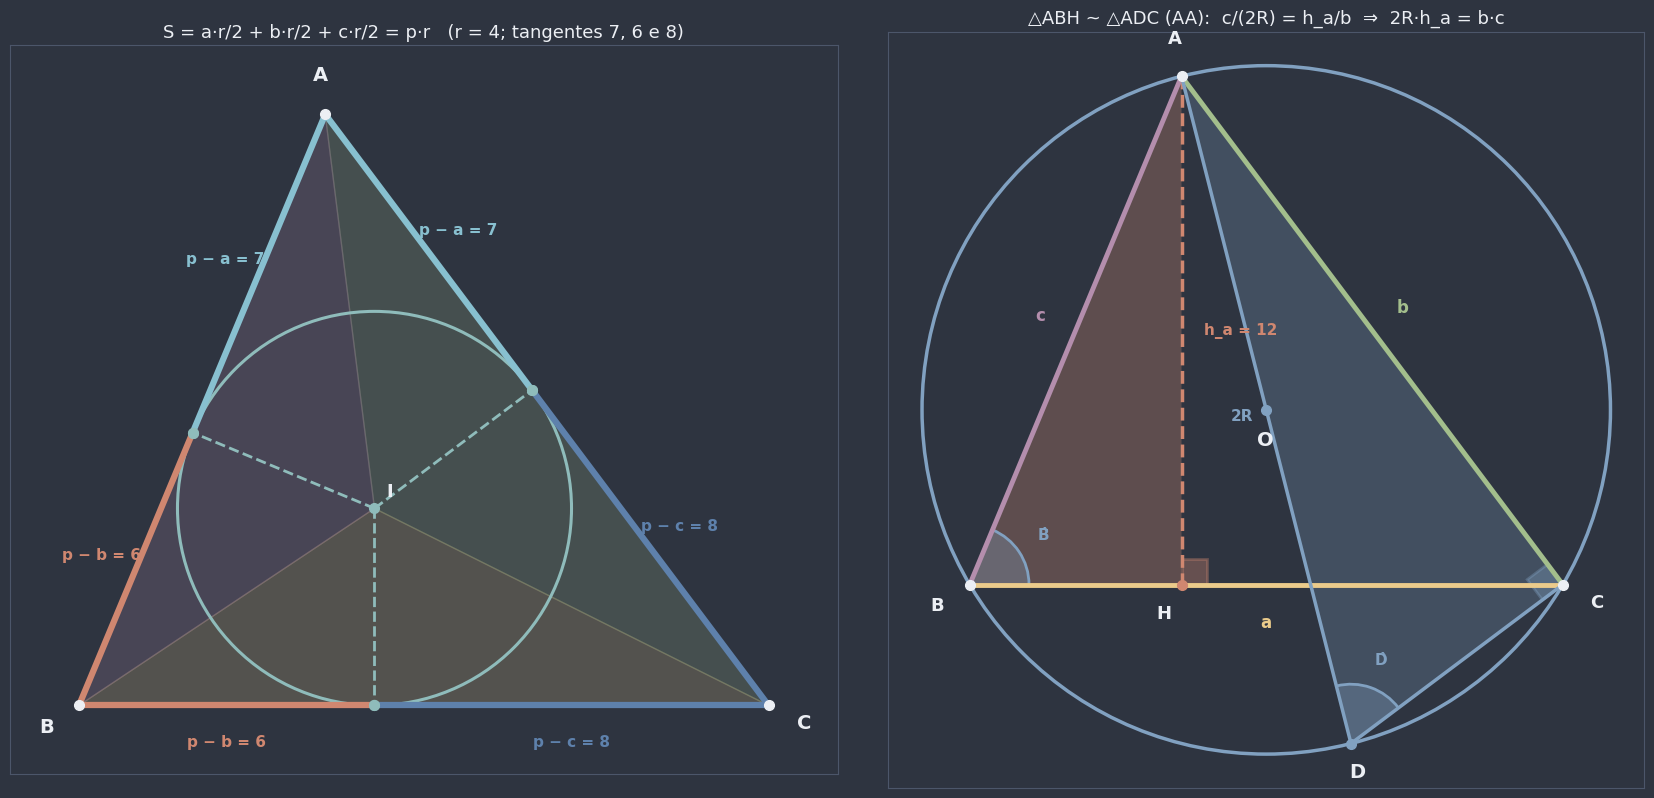

2R·h_a = 195   b·c = 195   →  R = 8.125


In [8]:
COR_TANGENTE = {"A": COR_PONTO, "B": COR_ALTURA, "C": "#5E81AC"}  # uma cor por vértice (ciano, laranja, azul)


def desenhar_tangentes(ax, A, B, C, tamanho: int = 11, valores: bool = True) -> None:
    """Circunferência inscrita com os seis segmentos tangentes, cada par na cor do vértice de onde sai
    (de A: p − a; de B: p − b; de C: p − c)."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    a, b, c = lados((A, B, C))
    I = incentro(A, B, C)
    r = distancia_ponto_reta(I, B, C)
    desenhar_circunferencia(ax, I, r, cor=COR_INSCRITA, largura=2.2)
    escala = max(a, b, c)
    for V, (P, Q), nome in ((A, (B, C), "A"), (B, (C, A), "B"), (C, (A, B), "C")):
        for X in (P, Q):
            T = pe_da_altura(I, V, X)  # ponto de tangência no lado VX
            texto = f"p − {nome.lower()}" + (f" = {math.dist(V, T):.3g}" if valores else "")
            desenhar_segmento(ax, V, T, cor=COR_TANGENTE[nome], largura=4.5)
            rotular_segmento(ax, V, T, texto, cor=COR_TANGENTE[nome], distancia=0.05 * escala, longe_de=I,
                             tamanho=tamanho)
            desenhar_ponto(ax, T, cor=COR_INSCRITA)


fig, (ax_r, ax_R) = plt.subplots(1, 2, figsize=(17, 8))
fig.patch.set_facecolor(NORD_FUNDO)

# S = p·r: três triângulos de vértice no incentro
A, B, C = triangulo_por_lados(14, 15, 13)
I = incentro(A, B, C)
for P, Q, cor in ((B, C, COR_LADO_A), (C, A, COR_LADO_B), (A, B, COR_LADO_C)):
    ax_r.add_patch(Polygon([I, P, Q], closed=True, facecolor=cor, alpha=0.2, edgecolor=cor, lw=1))
    desenhar_segmento(ax_r, I, pe_da_altura(I, P, Q), cor=COR_INSCRITA, largura=2, estilo="--")
desenhar_tangentes(ax_r, A, B, C)
for X, nome in ((A, "A"), (B, "B"), (C, "C")):
    desenhar_ponto(ax_r, X, cor=NORD_TEXTO)
    rotular_fora(ax_r, X, nome, I, distancia=0.8, tamanho=14)
desenhar_ponto(ax_r, I, "I", cor=COR_INSCRITA, deslocamento=(0.25, 0.25))
preparar_eixo(ax_r, [A, B, C], margem=1.4)
ax_r.set_title("S = a·r/2 + b·r/2 + c·r/2 = p·r   (r = 4; tangentes 7, 6 e 8)", color=NORD_TEXTO, fontsize=13)

# R = abc/(4S): o diâmetro AD e a semelhança ABH ~ ADC
O = circuncentro(A, B, C)
R = math.dist(O, A)
D = 2 * O - A  # a outra ponta do diâmetro que passa por A
H = pe_da_altura(A, B, C)
desenhar_circunferencia(ax_R, O, R, cor=COR_CIRCUNSCRITA)
ax_R.add_patch(Polygon([A, B, H], closed=True, facecolor=COR_ALTURA, alpha=0.3, edgecolor="none"))
ax_R.add_patch(Polygon([A, D, C], closed=True, facecolor=COR_CIRCUNSCRITA, alpha=0.25, edgecolor="none"))
desenhar_triangulo(ax_R, A, B, C, valores=False, preencher=False)
desenhar_segmento(ax_R, A, H, cor=COR_ALTURA, largura=2.5, estilo="--")
desenhar_segmento(ax_R, A, D, cor=COR_CIRCUNSCRITA, largura=2.5)
desenhar_segmento(ax_R, D, C, cor=COR_CIRCUNSCRITA, largura=2.5)
desenhar_setor(ax_R, H, 0, 90, raio=1.0, cor=COR_ALTURA)
desenhar_arco(ax_R, C, A, D, raio=1.0, cor=COR_CIRCUNSCRITA)
desenhar_arco(ax_R, B, A, C, raio=1.4, cor=COR_SECUNDARIA, rotulo="B̂", raio_rotulo=2.1)
desenhar_arco(ax_R, D, A, C, raio=1.4, cor=COR_SECUNDARIA, rotulo="D̂", raio_rotulo=2.1)
for X, nome in ((D, "D"), (O, "O")):
    desenhar_ponto(ax_R, X, cor=COR_CIRCUNSCRITA)
    rotular_fora(ax_R, X, nome, O + (0.01, 0.6), distancia=0.7, tamanho=14)
desenhar_ponto(ax_R, H, "H", cor=COR_ALTURA, deslocamento=(-0.6, -0.8))
rotular_segmento(ax_R, A, H, "h_a = 12", cor=COR_ALTURA, distancia=1.4, longe_de=B)
rotular_segmento(ax_R, A, D, "2R", cor=COR_CIRCUNSCRITA, distancia=0.6, longe_de=C)
preparar_eixo(ax_R, [O - (R, R), O + (R, R)], margem=0.8)
ax_R.set_title("△ABH ~ △ADC (AA):  c/(2R) = h_a/b  ⇒  2R·h_a = b·c", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()
print(f"2R·h_a = {2 * R * 12:g}   b·c = {15 * 13}   →  R = {R:g}")

⚠️ **Armadilha numérica (nível extra, ligação com computação):** a fórmula de Herão é exata no papel, mas no computador pode **perder precisão** em triângulos "agulha", em que um lado é quase a soma dos outros dois. O motivo: $p$ e $a$ ficam quase iguais, e a subtração $p - a$ de dois números grandes e quase iguais joga fora os algarismos significativos (o **cancelamento catastrófico**). O cientista da computação **William Kahan** propôs uma versão estável: ordenar os lados como $a \geq b \geq c$ e calcular

$$S = \frac{1}{4}\sqrt{\big(a + (b + c)\big)\big(c - (a - b)\big)\big(c + (a - b)\big)\big(a + (b - c)\big)},$$

**mantendo os parênteses exatamente assim** (no papel é a mesma conta do passo 4 da demonstração; no computador, a ordem das operações evita o cancelamento). A célula abaixo compara as duas com a área **exata**, calculada com frações (`fractions.Fraction`, que não arredonda nada) no triângulo de lados 100 000, 99 999,999 79 e 0,000 29.

In [9]:
def area_kahan(a: float, b: float, c: float) -> float:
    """Herão na forma estável de Kahan: ordena a ≥ b ≥ c e respeita os parênteses."""
    a, b, c = sorted((a, b, c), reverse=True)
    return 0.25 * math.sqrt((a + (b + c)) * (c - (a - b)) * (c + (a - b)) * (a + (b - c)))


def area_exata(a: float, b: float, c: float) -> float:
    """Herão com frações exatas (só a raiz final é arredondada)."""
    a, b, c = Fraction(a), Fraction(b), Fraction(c)
    return math.sqrt((a + b + c) * (-a + b + c) * (a - b + c) * (a + b - c) / 16)


agulha = (100_000, 99_999.99979, 0.00029)
exata = area_exata(*agulha)
for nome, valor in (("Herão direto", area_herao(*agulha)), ("Kahan", area_kahan(*agulha)), ("exata (frações)", exata)):
    print(f"{nome:>16}: {valor:.12f}   erro relativo: {abs(valor - exata) / exata:.1e}")

    Herão direto: 9.999999809638   erro relativo: 2.7e-08
           Kahan: 10.000000077021   erro relativo: 0.0e+00
 exata (frações): 10.000000077021   erro relativo: 0.0e+00


O Herão direto erra já na **oitava** casa (erro relativo de $10^{-8}$), enquanto o de Kahan acerta todos os algarismos. Para os triângulos "normais" deste notebook a diferença é desprezível, mas programas de engenharia e de computação gráfica, que lidam com milhões de triângulos finos, usam a versão estável. O Desafio 9 volta a esse assunto.

🕹️ **Widget interativo:** três sliders para os lados $a$, $b$ e $c$. Se o triângulo existir, ele é desenhado com a circunferência **inscrita** (verde-água), a **circunscrita** (azul) e os seis segmentos tangentes, cada par na cor do vértice de onde sai, e o painel recalcula $p$, $S$, $r$ e $R$ e confere com as medidas na figura. Se os sliders violarem a desigualdade triangular, o painel **avisa** qual lado é grande demais, em vez de quebrar. Experimente: $a = 6$, $b = 3$, $c = 3$ (achatado), e depois aumente um pouco $b$.

In [ ]:
def explorar_herao(a: float, b: float, c: float) -> None:
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 7), gridspec_kw={"width_ratios": [1.2, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    p = semiperimetro(a, b, c)
    if not existe_triangulo(a, b, c):
        maior, nome = max((a, "a"), (b, "b"), (c, "c"))
        resto = a + b + c - maior
        estilizar_eixo(ax)
        ax.axis("off")
        ax.text(0.5, 0.5, f"NÃO EXISTE TRIÂNGULO\n\n{nome} = {maior:g} ≥ {resto:g} = soma dos outros dois",
                color=COR_ALERTA, fontsize=16, fontweight="bold", ha="center", va="center", transform=ax.transAxes)
        radicando = p * (p - a) * (p - b) * (p - c)
        itens = [(f"p = {p:g}", True),
                 (f"p − {nome} = {p - maior:g} (deveria ser positivo)", False),
                 (f"radicando p(p − a)(p − b)(p − c) = {radicando:g}", radicando > 0),
                 ("a fórmula de Herão avisa: sem raiz real (ou área 0)", False)]
        escrever_checklist(ax_lista, itens, "Desigualdade triangular violada")
        plt.tight_layout()
        plt.show()
        return

    A, B, C = triangulo_por_lados(a, b, c)
    S, r, R = area_herao(a, b, c), raio_inscrito(a, b, c), raio_circunscrito(a, b, c)
    I, O = incentro(A, B, C), circuncentro(A, B, C)
    desenhar_triangulo(ax, A, B, C, valores=False, tamanho=11)
    desenhar_tangentes(ax, A, B, C, tamanho=10)
    desenhar_ponto(ax, I, "I", cor=COR_INSCRITA)
    escala = max(a, b, c)
    if R < 2.5 * escala:
        desenhar_circunferencia(ax, O, R, cor=COR_CIRCUNSCRITA, largura=2)
        desenhar_ponto(ax, O, "O", cor=COR_CIRCUNSCRITA)
        preparar_eixo(ax, [O - (R, R), O + (R, R), A, B, C], margem=0.6)
    else:
        preparar_eixo(ax, [A, B, C], margem=0.15 * escala)
        ax.text(0.5, 0.02, "(circunscrita grande demais para caber)", color=COR_CIRCUNSCRITA, fontsize=10,
                ha="center", transform=ax.transAxes)
    ax.set_title(f"triângulo {classifica_por_lados(a, b, c)}", color=NORD_TEXTO, fontsize=13)
    x, y, z = segmentos_tangentes(a, b, c)
    itens = [
        (f"p = {p:.3f};  tangentes: p − a = {x:.2f}, p − b = {y:.2f}, p − c = {z:.2f}", True),
        (f"S (Herão) = {S:.4f}", True),
        (f"S = a·h_a/2 = {a * distancia_ponto_reta(A, B, C) / 2:.4f}", iguais(S, a * distancia_ponto_reta(A, B, C) / 2)),
        (f"r = S/p = {r:.4f}   (medido: {distancia_ponto_reta(I, B, C):.4f})", iguais(r, distancia_ponto_reta(I, B, C))),
        (f"R = abc/(4S) = {R:.4f}   (medido: {math.dist(O, A):.4f})", iguais(R, math.dist(O, A))),
        (f"S = p·r = {p * r:.4f}", iguais(S, p * r)),
        (f"R ≥ 2r:  {R:.3f} ≥ {2 * r:.3f}", R >= 2 * r - 1e-9),
    ]
    escrever_checklist(ax_lista, itens, f"a = {a:g}, b = {b:g}, c = {c:g}")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_herao,
    a=widgets.FloatSlider(value=14, min=1, max=16, step=0.5, description="a:"),
    b=widgets.FloatSlider(value=15, min=1, max=16, step=0.5, description="b:"),
    c=widgets.FloatSlider(value=13, min=1, max=16, step=0.5, description="c:"),
);

interactive(children=(FloatSlider(value=14.0, description='a:', max=16.0, min=1.0, step=0.5), FloatSlider(valu…

Repare na última linha do painel: $R \geq 2r$ em todos os triângulos que você testar, com igualdade só no equilátero. É a **desigualdade de Euler**, que fica para o Desafio 8.

🎯 **Aplicação prática — agrimensura e triangulação:** medir um ângulo no campo exige instrumento; medir distâncias, só uma trena (ou uma corrente de agrimensor). Por isso, para calcular a área de um terreno irregular, divide-se o terreno em **triângulos**, medem-se os lados de cada um e soma-se as áreas por Herão. A mesma ideia de cobrir uma região por triângulos é a base da **triangulação**, que sustentou a cartografia por séculos e, com distâncias medidas por sinais de rádio, está por trás do posicionamento por GPS.

⚠️ **Erro comum: usar o perímetro no lugar do semiperímetro.** Com $2p = 42$ no terreno, sairia $\sqrt{42 \cdot 28 \cdot 27 \cdot 29}$, um absurdo. Regra de bolso: o produto tem **quatro** fatores, cada um com dimensão de comprimento, e a raiz de "comprimento⁴" é "comprimento²", que é dimensão de **área**. Se a conta der dimensão errada, a fórmula está errada.

📖 **Leitura complementar:** [Fórmula de Herão](https://pt.wikipedia.org/wiki/F%C3%B3rmula_de_Heron) (Wikipédia; o verbete se chama "Teorema de Herão" e traz várias demonstrações).

**Pergunta de checagem:** qual é a área de um triângulo de lados 5, 5 e 6? E o raio da circunferência inscrita?

**Pergunta de checagem:** por que $(p - a) + (p - b) = c$? Use isso para explicar por que, no radicando de Herão, nunca dois fatores são negativos ao mesmo tempo.

## 3. O teorema da mediana

A **mediana** $m_a$ é o segmento que liga o vértice $A$ ao ponto médio $M$ do lado oposto ([`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)). Quanto ela mede, só com os lados?

A mediana divide o triângulo em dois, $ABM$ e $ACM$, que **compartilham** o lado $\overline{AM}$ e têm $BM = MC = \frac{a}{2}$. Os ângulos $A\hat{M}B$ e $A\hat{M}C$ são **suplementares** ([`0403a_angulos.ipynb`](0403a_angulos.ipynb)): se um é agudo, o outro é obtuso. Seja $x$ a projeção de $\overline{AM}$ sobre a reta $BC$ (a distância de $M$ ao pé $H$ da altura). Aplicando a relação da seção 1 nos dois triângulos, com o ângulo em $M$ (digamos que $A\hat{M}B$ seja o agudo):

$$c^2 = m_a^2 + \left(\tfrac{a}{2}\right)^2 - 2 \cdot \tfrac{a}{2} \cdot x \qquad\qquad b^2 = m_a^2 + \left(\tfrac{a}{2}\right)^2 + 2 \cdot \tfrac{a}{2} \cdot x$$

**Somando**, os termos com $x$ se cancelam:

$$b^2 + c^2 = 2m_a^2 + \frac{a^2}{2} \qquad\Longrightarrow\qquad m_a^2 = \frac{2b^2 + 2c^2 - a^2}{4}. \qquad \blacksquare$$

(Se a mediana for perpendicular ao lado, $x = 0$ e as duas relações são Pitágoras puro.)

📌 **Definição formal (teorema da mediana):** a mediana relativa ao lado $a$ mede

$$m_a = \frac{1}{2}\sqrt{2b^2 + 2c^2 - a^2},$$

e analogamente $m_b = \frac{1}{2}\sqrt{2a^2 + 2c^2 - b^2}$ e $m_c = \frac{1}{2}\sqrt{2a^2 + 2b^2 - c^2}$. O resultado costuma ser atribuído a **Apolônio de Perga** (século III a.C.) e também é conhecido como **teorema de Apolônio**.

No terreno: $m_a^2 = \frac{2 \cdot 225 + 2 \cdot 169 - 196}{4} = \frac{592}{4} = 148$, isto é, $m_a = \sqrt{148} \approx 12{,}17$ m.

### Corolários

1. **Triângulo retângulo** (fechando a promessa de 0410a e 0416a): se $a$ é a hipotenusa, $b^2 + c^2 = a^2$ e $m_a^2 = \frac{2a^2 - a^2}{4} = \frac{a^2}{4}$, isto é, $m_a = \frac{a}{2}$. A mediana relativa à hipotenusa mede metade dela, agora como **caso particular**.
2. **Soma dos quadrados das medianas:** somando as três fórmulas, $m_a^2 + m_b^2 + m_c^2 = \frac{3}{4}\left(a^2 + b^2 + c^2\right)$.
3. **Distâncias do baricentro aos vértices:** o baricentro $G$ divide cada mediana na razão $2 : 1$ (0410a, demonstrado no desafio de 0414a), então $GA = \frac{2}{3} m_a$, e somando os quadrados: $GA^2 + GB^2 + GC^2 = \frac{4}{9} \cdot \frac{3}{4}\left(a^2 + b^2 + c^2\right) = \frac{1}{3}\left(a^2 + b^2 + c^2\right)$.
4. **Paralelogramo:** num paralelogramo $ABCD$ de lados $AB = x$ e $AD = y$, as diagonais se cortam no ponto médio $O$ ([`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)). No triângulo $ABD$, $\overline{AO}$ é a mediana relativa a $\overline{BD}$ e mede $\frac{AC}{2}$; pelo teorema, $\frac{AC^2}{4} = \frac{2x^2 + 2y^2 - BD^2}{4}$, isto é, $AC^2 + BD^2 = 2x^2 + 2y^2$: **a soma dos quadrados das diagonais é a soma dos quadrados dos quatro lados**.
5. **Triângulo medial** (cumprindo a promessa da base média de [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb)): ligando os pontos médios dos três lados, cada lado do novo triângulo é uma **base média**, paralela a um lado do original e com metade da medida: $\frac{a}{2}$, $\frac{b}{2}$, $\frac{c}{2}$. Pelo critério LLL de semelhança (0415a), o triângulo medial é semelhante ao original na razão $1 : 2$, e as medianas dele passam pelo **mesmo** baricentro $G$.

**No código:** `mediana(a, b, c, qual="a")` aplica a fórmula ao lado escolhido e `medianas(a, b, c)` devolve as três. A célula compara com as distâncias de cada vértice ao ponto médio do lado oposto, confere os corolários 2 a 5 com `assert` em triângulos sorteados e mede os lados do triângulo medial.

In [11]:
def mediana(a: float, b: float, c: float, qual: str = "a") -> float:
    """Comprimento da mediana relativa ao lado `qual` ("a", "b" ou "c"): m_a = ½·√(2b² + 2c² − a²)."""
    oposto, outros = {"a": (a, (b, c)), "b": (b, (a, c)), "c": (c, (a, b))}[qual]
    return math.sqrt(2 * outros[0] ** 2 + 2 * outros[1] ** 2 - oposto**2) / 2


def medianas(a: float, b: float, c: float) -> tuple[float, float, float]:
    """As três medianas (m_a, m_b, m_c)."""
    return mediana(a, b, c, "a"), mediana(a, b, c, "b"), mediana(a, b, c, "c")


# O terreno: fórmula × medida (distância do vértice ao ponto médio do lado oposto)
A, B, C = triangulo_por_lados(14, 15, 13)
medidas = (math.dist(A, ponto_medio(B, C)), math.dist(B, ponto_medio(C, A)), math.dist(C, ponto_medio(A, B)))
display(pd.DataFrame([{"mediana": nome, "fórmula": f"{x:.6f}", "medida": f"{y:.6f}", "m²": f"{x**2:g}",
                       "confere?": "✅" if iguais(x, y) else "❌"}
                      for nome, x, y in zip(("m_a", "m_b", "m_c"), medianas(14, 15, 13), medidas)]))

# Corolários conferidos em 500 triângulos sorteados
gerador = np.random.default_rng(3)
for _ in range(500):
    A, B, C = gerador.uniform(-10, 10, size=(3, 2))
    a, b, c = lados((A, B, C))
    if not existe_triangulo(a, b, c):
        continue
    ma, mb, mc = medianas(a, b, c)
    G = baricentro(A, B, C)
    assert iguais(ma, math.dist(A, ponto_medio(B, C)))  # a própria fórmula
    assert iguais(ma**2 + mb**2 + mc**2, 3 / 4 * (a**2 + b**2 + c**2))  # corolário 2
    assert iguais(math.dist(G, A), 2 / 3 * ma)  # corolário 3
    assert iguais(math.dist(G, A) ** 2 + math.dist(G, B) ** 2 + math.dist(G, C) ** 2, (a**2 + b**2 + c**2) / 3)
    D = A + C - B  # ABCD paralelogramo (corolário 4)
    assert iguais(math.dist(A, C) ** 2 + math.dist(B, D) ** 2, 2 * math.dist(A, B) ** 2 + 2 * math.dist(B, C) ** 2)
    medial = (ponto_medio(B, C), ponto_medio(C, A), ponto_medio(A, B))  # corolário 5
    assert all(iguais(x, y / 2) for x, y in zip(lados(medial), (a, b, c)))
    assert np.allclose(baricentro(*medial), G)
print("corolários 2, 3, 4 e 5 conferidos em todos os triângulos sorteados ✅")

# Corolário 1: no triângulo retângulo, a mediana relativa à hipotenusa é a metade dela
for a, b, c in ((5, 4, 3), (13, 12, 5), (25, 24, 7)):
    print(f"hipotenusa a = {a}: m_a = {mediana(a, b, c):g} = a/2")

,mediana,fórmula,medida,m²,confere?
0,m_a,12.165525,12.165525,148,✅
1,m_b,11.236103,11.236103,126.25,✅
2,m_c,12.971122,12.971122,168.25,✅


corolários 2, 3, 4 e 5 conferidos em todos os triângulos sorteados ✅
hipotenusa a = 5: m_a = 2.5 = a/2
hipotenusa a = 13: m_a = 6.5 = a/2
hipotenusa a = 25: m_a = 12.5 = a/2


A representação gráfica. À esquerda, a demonstração no terreno: a mediana $\overline{AM}$ (azul-claro) divide o triângulo em $ABM$ (roxo, ângulo **agudo** em $M$) e $ACM$ (verde, ângulo **obtuso** em $M$); a projeção $x = MH = 2$ entra com sinal **menos** num e **mais** no outro, e some na soma. À direita, as três medianas, o baricentro $G$ e o **triângulo medial** (tracejado), com lados $7$, $7{,}5$ e $6{,}5$: metade de $14$, $15$ e $13$.

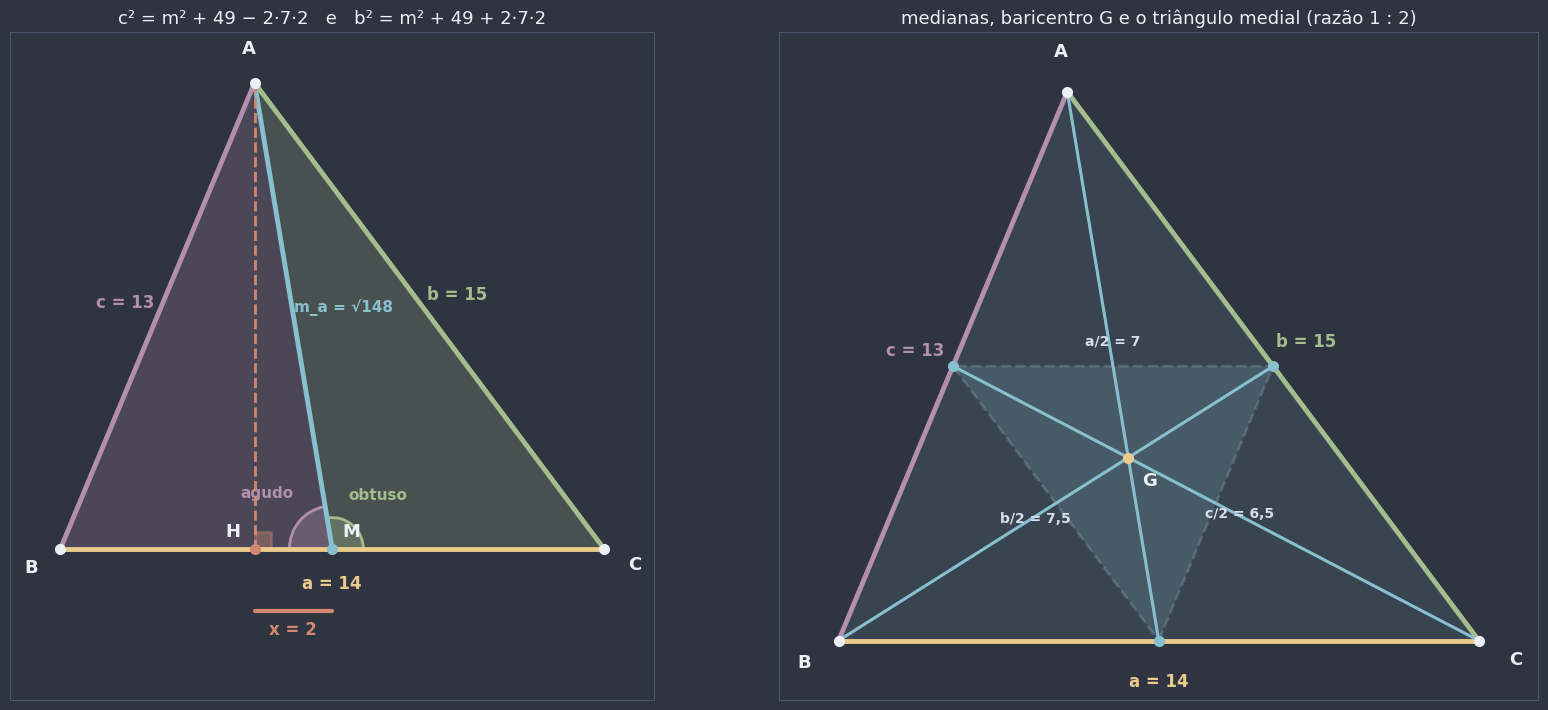

In [12]:
fig, (ax_d, ax_m) = plt.subplots(1, 2, figsize=(17, 7.2))
fig.patch.set_facecolor(NORD_FUNDO)
A, B, C = triangulo_por_lados(14, 15, 13)
M, H = ponto_medio(B, C), pe_da_altura(A, B, C)

# A demonstração: ABM (agudo em M) e ACM (obtuso em M)
ax_d.add_patch(Polygon([A, B, M], closed=True, facecolor=COR_LADO_C, alpha=0.22, edgecolor="none"))
ax_d.add_patch(Polygon([A, M, C], closed=True, facecolor=COR_LADO_B, alpha=0.22, edgecolor="none"))
desenhar_triangulo(ax_d, A, B, C, preencher=False)
desenhar_segmento(ax_d, A, M, cor=COR_MEDIANA, largura=3.5)
desenhar_segmento(ax_d, A, H, cor=COR_ALTURA, largura=2, estilo="--")
desenhar_setor(ax_d, H, 0, 90, raio=0.7, cor=COR_ALTURA)
desenhar_arco(ax_d, M, B, A, raio=1.1, cor=COR_LADO_C, rotulo="agudo", raio_rotulo=2.2)
desenhar_arco(ax_d, M, A, C, raio=0.8, cor=COR_LADO_B, rotulo="obtuso", raio_rotulo=1.8)
desenhar_segmento(ax_d, H + (0, -1.6), M + (0, -1.6), cor=COR_ALTURA, largura=3)
ax_d.text(*(ponto_medio(H, M) + (0, -2.2)), "x = 2", color=COR_ALTURA, fontsize=12, fontweight="bold", ha="center")
rotular_segmento(ax_d, A, M, "m_a = √148", cor=COR_MEDIANA, distancia=1.3, longe_de=B)
desenhar_ponto(ax_d, M, "M", cor=COR_MEDIANA, deslocamento=(0.25, 0.3))
desenhar_ponto(ax_d, H, "H", cor=COR_ALTURA, deslocamento=(-0.75, 0.3))
preparar_eixo(ax_d, [A, B, C, (0, -2.6)], margem=1.3)
ax_d.set_title("c² = m² + 49 − 2·7·2   e   b² = m² + 49 + 2·7·2", color=NORD_TEXTO, fontsize=13)

# As três medianas, o baricentro e o triângulo medial
medial = [ponto_medio(B, C), ponto_medio(C, A), ponto_medio(A, B)]
desenhar_triangulo(ax_m, A, B, C)
ax_m.add_patch(Polygon(medial, closed=True, facecolor=COR_MEDIANA, alpha=0.18, edgecolor=NORD_TEXTO_SEC, lw=2,
                       ls="--"))
for V, P in zip((A, B, C), medial):
    desenhar_segmento(ax_m, V, P, cor=COR_MEDIANA, largura=2.2)
    desenhar_ponto(ax_m, P, cor=COR_MEDIANA)
for P, Q, base in ((medial[1], medial[2], "a/2 = 7"), (medial[2], medial[0], "b/2 = 7,5"),
                   (medial[0], medial[1], "c/2 = 6,5")):
    rotular_segmento(ax_m, P, Q, base, cor=NORD_TEXTO_SEC, distancia=0.55, longe_de=baricentro(A, B, C), tamanho=10)
desenhar_ponto(ax_m, baricentro(A, B, C), "G", cor=COR_AVISO, deslocamento=(0.3, -0.6))
preparar_eixo(ax_m, [A, B, C], margem=1.3)
ax_m.set_title("medianas, baricentro G e o triângulo medial (razão 1 : 2)", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo:** $B = (0, 0)$ e $C = (8, 0)$ estão fixos, e os sliders `x` e `y` movem o vértice $A$. A figura mostra as três medianas e o baricentro $G$; o painel compara, em tempo real, cada mediana **pela fórmula** e **pela distância** na figura, a soma $m_a^2 + m_b^2 + m_c^2$ com $\frac{3}{4}(a^2 + b^2 + c^2)$ e a razão $GA = \frac{2}{3} m_a$. Procure uma posição de $A$ em que $m_a = \frac{a}{2} = 4$: onde ficam todos esses pontos?

In [13]:
def explorar_medianas(x: float, y: float) -> None:
    A, B, C = np.array([x, y]), np.array([0.0, 0.0]), np.array([8.0, 0.0])
    a, b, c = lados((A, B, C))
    G = baricentro(A, B, C)
    pontos_medios = (ponto_medio(B, C), ponto_medio(C, A), ponto_medio(A, B))
    pela_formula = medianas(a, b, c)
    pela_medida = tuple(math.dist(V, P) for V, P in zip((A, B, C), pontos_medios))

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.25, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_triangulo(ax, A, B, C, tamanho=11)
    for V, P in zip((A, B, C), pontos_medios):
        desenhar_segmento(ax, V, P, cor=COR_MEDIANA, largura=2.5)
        desenhar_ponto(ax, P, cor=COR_MEDIANA)
    desenhar_ponto(ax, G, "G", cor=COR_AVISO, deslocamento=(0.2, -0.45))
    preparar_eixo(ax, [(-4.5, -1), (12.5, 8.5)], margem=0.3)
    ax.set_title(f"A = ({x:g}, {y:g})  →  triângulo {classifica_por_lados(a, b, c)}", color=NORD_TEXTO, fontsize=13)
    itens = [(f"{nome}: fórmula {f:.4f}  ×  medida {m:.4f}", iguais(f, m))
             for nome, f, m in zip(("m_a", "m_b", "m_c"), pela_formula, pela_medida)]
    soma = sum(m**2 for m in pela_formula)
    itens += [
        (f"m_a² + m_b² + m_c² = {soma:.3f} = ¾·(a² + b² + c²) = {0.75 * (a**2 + b**2 + c**2):.3f}",
         iguais(soma, 0.75 * (a**2 + b**2 + c**2))),
        (f"GA = {math.dist(G, A):.4f} = ⅔·m_a = {2 / 3 * pela_formula[0]:.4f}", iguais(math.dist(G, A), 2 / 3 * pela_formula[0])),
        (f"m_a = {pela_formula[0]:.3f}  ×  a/2 = 4  ({'iguais: ângulo reto em A!' if iguais(pela_formula[0], 4) else 'diferentes'})",
         iguais(pela_formula[0], 4)),
    ]
    escrever_checklist(ax_lista, itens, f"a = {a:.3f}, b = {b:.3f}, c = {c:.3f}")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_medianas,
    x=widgets.FloatSlider(value=2.5, min=-4, max=12, step=0.5, description="x de A:"),
    y=widgets.FloatSlider(value=5.5, min=1, max=8, step=0.5, description="y de A:"),
);

interactive(children=(FloatSlider(value=2.5, description='x de A:', max=12.0, min=-4.0, step=0.5), FloatSlider…

Quando $m_a = 4$, o ponto $A$ está a 4 unidades do ponto médio $M = (4, 0)$, isto é, na **circunferência de diâmetro $\overline{BC}$**, e o ângulo em $A$ é reto (0413a). Experimente $A = (4, 4)$: a fórmula da mediana "enxerga" o ângulo reto.

🎯 **Aplicação prática — física, o centro de massa:** o baricentro de uma placa triangular **homogênea** (de espessura e material uniformes) é o seu **centro de massa**: apoiada num único ponto exatamente em $G$, a placa fica em equilíbrio. Pelos corolários, dá para saber, só com uma trena, a que distância de cada vértice fica esse ponto: $GA = \frac{2}{3} m_a$. Numa placa com o formato do terreno (13, 14 e 15 cm), $GA = \frac{2}{3}\sqrt{148} \approx 8{,}11$ cm.

💡 **Dica:** a fórmula da mediana conecta **quatro** números: três lados e uma mediana. Dados quaisquer três deles, o quarto sai dela. Por exemplo, se $b = 7$, $c = 9$ e $m_a = 7$, então $a^2 = 2 \cdot 49 + 2 \cdot 81 - 4 \cdot 49 = 64$ e $a = 8$.

⚠️ **Erro comum: trocar o sinal do lado oposto.** Na fórmula $m_a^2 = \frac{2b^2 + 2c^2 - a^2}{4}$, o lado que entra com sinal **menos** é aquele **sobre o qual a mediana cai** (o lado $a$, que ela corta ao meio). Teste rápido: no triângulo retângulo com hipotenusa $a$, tem de sair $m_a = \frac{a}{2}$.

📖 **Leitura complementar:** [Mediana (geometria)](https://pt.wikipedia.org/wiki/Mediana_(geometria)) (Wikipédia).

**Pergunta de checagem:** num triângulo de lados 13, 14 e 15, qual é a mediana relativa ao lado 14? E a distância do vértice $A$ ao baricentro?

**Pergunta de checagem:** um paralelogramo tem lados 5 e 7 e uma diagonal de 8. Quanto mede a outra diagonal?

## 4. O teorema de Stewart e o comprimento da bissetriz

Uma **ceviana** é qualquer segmento que liga um vértice a um ponto da reta do lado oposto. Altura, mediana e bissetriz são cevianas especiais; a seção 3 mediu a mediana. Agora, **qualquer** ceviana.

Seja $D$ um ponto do lado $\overline{BC}$ com $BD = m$ e $DC = n$ (então $m + n = a$), e seja $d = AD$.

⚠️ **Atenção à notação:** nesta seção, $m$ e $n$ são as duas **partes** em que $D$ divide o lado $a$, e **não** as projeções da seção 1. Nas figuras elas têm cores próprias: $m = BD$ em azul-escuro e $n = DC$ em verde-água.

Os ângulos $A\hat{D}B$ e $A\hat{D}C$ são suplementares (um agudo e outro obtuso, ou os dois retos). Seja $x$ a projeção de $\overline{AD}$ sobre a reta $BC$. A relação da seção 1, nos triângulos $ABD$ e $ADC$ (digamos que o agudo seja $A\hat{D}B$):

$$c^2 = d^2 + m^2 - 2 \cdot m \cdot x \qquad\qquad b^2 = d^2 + n^2 + 2 \cdot n \cdot x$$

Agora o truque: multiplicar a primeira por $n$ e a segunda por $m$, para que os termos com $x$ fiquem iguais ($2mnx$) e se cancelem na soma:

$$c^2 n + b^2 m = d^2(m + n) + m^2 n + n^2 m = a \cdot d^2 + mn(m + n) = a\left(d^2 + mn\right). \qquad \blacksquare$$

📌 **Definição formal (teorema de Stewart):** se $D$ está no lado $\overline{BC}$, com $BD = m$, $DC = n$ e $AD = d$, então

$$b^2 \cdot m + c^2 \cdot n = a \cdot \left(d^2 + m \cdot n\right).$$

| Ceviana | Onde fica $D$ | O que Stewart vira |
|---|---|---|
| **mediana** | $m = n = \frac{a}{2}$ | $\frac{a}{2}(b^2 + c^2) = a\left(m_a^2 + \frac{a^2}{4}\right)$: o teorema da mediana da seção 3 |
| **altura** | $D = H$ | com $b^2 = h^2 + n^2$ e $c^2 = h^2 + m^2$: $h^2(m + n) + mn(n + m) = a(h^2 + mn)$, Pitágoras duas vezes |
| **bissetriz interna** | $\frac{m}{n} = \frac{c}{b}$ | $t_a^2 = bc - mn$ (abaixo) |

### O comprimento da bissetriz

Cumprindo a promessa de [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb), que disse **onde** a bissetriz cai: pelo **teorema da bissetriz interna**, $\frac{BD}{DC} = \frac{AB}{AC} = \frac{c}{b}$; como $m + n = a$,

$$m = \frac{a \cdot c}{b + c} \qquad\qquad n = \frac{a \cdot b}{b + c}.$$

Substituindo em Stewart: $b^2 \cdot \frac{ac}{b + c} + c^2 \cdot \frac{ab}{b + c} = \frac{abc(b + c)}{b + c} = abc$. Então $abc = a(t_a^2 + mn)$, e dividindo por $a$:

$$t_a^2 = b \cdot c - m \cdot n = bc\left[1 - \frac{a^2}{(b + c)^2}\right], \qquad\text{isto é,}\qquad t_a = \frac{2}{b + c}\sqrt{b \cdot c \cdot p \cdot (p - a)}.$$

(Na última passagem: $(b + c)^2 - a^2 = (b + c - a)(b + c + a) = 2(p - a) \cdot 2p$.)

### A mesma conclusão pela potência de ponto

Cumprindo a promessa de [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb): prolongue a bissetriz $\overline{AD}$ até cortar a circunferência circunscrita no ponto $E$.

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $B\hat{A}D = E\hat{A}C$ | $\overline{AE}$ é a bissetriz de $\hat{A}$ |
| 2 | $A\hat{B}D = A\hat{E}C$ | ângulos inscritos que enxergam o mesmo arco $\overset{\frown}{AC}$ ([`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)) |
| 3 | $\triangle ABD \sim \triangle AEC$, logo $\frac{AB}{AE} = \frac{AD}{AC}$ | critério **AA** |
| 4 | $AD \cdot AE = b \cdot c$ | multiplicando "em cruz" |
| 5 | $AD \cdot DE = BD \cdot DC = m \cdot n$ | potência do ponto $D$: duas cordas que se cortam em $D$ |
| 6 | $AD \cdot (AE - DE) = AD \cdot AD = bc - mn$ | subtraindo 4 − 5, pois $AE - DE = AD$ |

Dois caminhos independentes (Stewart e potência de ponto), **o mesmo** resultado: $t_a^2 = bc - mn$. $\blacksquare$

### A razão do incentro

Cumprindo o desafio de 0414a: o incentro $I$ está sobre a bissetriz $\overline{AD}$, e $\overline{BI}$ é a bissetriz do ângulo $\hat{B}$ no triângulo $ABD$. Pelo teorema da bissetriz interna **nesse** triângulo:

$$\frac{AI}{ID} = \frac{AB}{BD} = \frac{c}{m} = \frac{c(b + c)}{ac} = \frac{b + c}{a}.$$

**No terreno** ($a = 14$, $b = 15$, $c = 13$): $m = \frac{14 \cdot 13}{28} = 6{,}5$, $n = 7{,}5$, $t_a^2 = 195 - 48{,}75 = 146{,}25$, $t_a \approx 12{,}09$ e $\frac{AI}{ID} = \frac{28}{14} = 2$. Compare as três cevianas de $A$: altura $12$, bissetriz $\approx 12{,}09$, mediana $\approx 12{,}17$. A altura é a **menor** e a mediana a **maior**, e a ordem **altura ≤ bissetriz ≤ mediana** (traçadas do mesmo vértice) vale em **todo** triângulo, com igualdade só quando $b = c$.

**No código:** `stewart(a, b, c, m)` devolve $d = AD$ para $BD = m$; `pe_da_bissetriz(a, b, c)` devolve $(m, n)$; `bissetriz(a, b, c, qual="a")` usa a fórmula com $p$. A célula confere as três cevianas do terreno contra as coordenadas, testa Stewart em pontos $D$ sorteados, mede $AI/ID$ e verifica a ordem altura ≤ bissetriz ≤ mediana em 10 000 triângulos.

In [14]:
def stewart(a: float, b: float, c: float, m: float) -> float:
    """Comprimento d = AD da ceviana que chega ao ponto D de BC com BD = m (0 ≤ m ≤ a), pelo teorema de Stewart:
    b²·m + c²·n = a·(d² + m·n), com n = a − m."""
    n = a - m
    return math.sqrt((b**2 * m + c**2 * n) / a - m * n)


def pe_da_bissetriz(a: float, b: float, c: float) -> tuple[float, float]:
    """Partes (m, n) = (BD, DC) em que a bissetriz de A divide o lado a: BD/DC = c/b (0414a)."""
    return a * c / (b + c), a * b / (b + c)


def bissetriz(a: float, b: float, c: float, qual: str = "a") -> float:
    """Comprimento da bissetriz interna traçada até o lado `qual`: t_a = 2·√(b·c·p·(p − a)) / (b + c)."""
    oposto, (x, y) = {"a": (a, (b, c)), "b": (b, (a, c)), "c": (c, (a, b))}[qual]
    p = semiperimetro(a, b, c)
    return 2 * math.sqrt(x * y * p * (p - oposto)) / (x + y)


a, b, c = 14, 15, 13
A, B, C = triangulo_por_lados(a, b, c)
H = pe_da_altura(A, B, C)
m_bis, n_bis = pe_da_bissetriz(a, b, c)
cevianas = [("altura", math.dist(B, H)), ("bissetriz", m_bis), ("mediana", a / 2)]
linhas = []
for nome, m in cevianas:
    D = B + m / a * (C - B)
    linhas.append({"ceviana de A": nome, "BD = m": f"{m:g}", "DC = n": f"{a - m:g}",
                   "d por Stewart": f"{stewart(a, b, c, m):.6f}", "d medido": f"{math.dist(A, D):.6f}",
                   "confere?": "✅" if iguais(stewart(a, b, c, m), math.dist(A, D)) else "❌"})
display(pd.DataFrame(linhas))
print(f"bissetriz: t_a² = bc − mn = {b * c} − {m_bis * n_bis:g} = {b * c - m_bis * n_bis:g};  pela fórmula com p: "
      f"t_a = {bissetriz(a, b, c):.6f} = √{bissetriz(a, b, c) ** 2:.6g}")

# A bissetriz pelas coordenadas: a reta que divide o ângulo A ao meio cruza BC em D
u = (B - A) / math.dist(A, B) + (C - A) / math.dist(A, C)  # soma dos vetores unitários: aponta "pelo meio" do ângulo
D_bis = cruzamento(A, direcao_de(A, A + u), B, direcao_de(B, C))
I = incentro(A, B, C)
print(f"pé da bissetriz medido: BD = {math.dist(B, D_bis):g}, DC = {math.dist(D_bis, C):g}")
print(f"AI/ID = {math.dist(A, I) / math.dist(I, D_bis):g}   (b + c)/a = {(b + c) / a:g}")

# Stewart para pontos D sorteados e a ordem altura ≤ bissetriz ≤ mediana
gerador = np.random.default_rng(14)
maior_erro, violacoes, testados = 0.0, 0, 0
for _ in range(10_000):
    A, B, C = gerador.uniform(-10, 10, size=(3, 2))
    a, b, c = lados((A, B, C))
    if a * distancia_ponto_reta(A, B, C) / 2 < 0.5:  # descarta os quase achatados
        continue
    testados += 1
    t = gerador.uniform(0, 1)
    D = B + t * (C - B)
    maior_erro = max(maior_erro, abs(stewart(a, b, c, t * a) - math.dist(A, D)))
    for vertice, P, Q, qual in ((A, B, C, "a"), (B, C, A, "b"), (C, A, B, "c")):
        h = distancia_ponto_reta(vertice, P, Q)
        if not h <= bissetriz(a, b, c, qual) + 1e-9 <= mediana(a, b, c, qual) + 2e-9:
            violacoes += 1
print(f"{testados} triângulos: maior erro de Stewart = {maior_erro:.1e};  "
      f"violações de altura ≤ bissetriz ≤ mediana: {violacoes} (em {3 * testados} vértices)")
assert maior_erro < 1e-8 and violacoes == 0

,ceviana de A,BD = m,DC = n,d por Stewart,d medido,confere?
0,altura,5,9,12.000000,12.000000,✅
1,bissetriz,6.5,7.5,12.093387,12.093387,✅
2,mediana,7,7,12.165525,12.165525,✅


bissetriz: t_a² = bc − mn = 195 − 48.75 = 146.25;  pela fórmula com p: t_a = 12.093387 = √146.25
pé da bissetriz medido: BD = 6.5, DC = 7.5
AI/ID = 2   (b + c)/a = 2
9840 triângulos: maior erro de Stewart = 2.1e-14;  violações de altura ≤ bissetriz ≤ mediana: 0 (em 29520 vértices)


Stewart acerta as três cevianas do terreno (altura 12, bissetriz $\sqrt{146{,}25}$, mediana $\sqrt{148}$), o pé da bissetriz achado pelas coordenadas confirma $BD = 6{,}5$ e $DC = 7{,}5$, e o incentro divide a bissetriz na razão $AI/ID = 2$. Nos 10 000 sorteios, Stewart nunca erra mais que os arredondamentos e a ordem altura ≤ bissetriz ≤ mediana **nunca** falha.

A representação gráfica das duas demonstrações. À esquerda, Stewart com uma ceviana qualquer ($BD = 11$): os triângulos $ABD$ (roxo) e $ADC$ (verde) dividem a projeção $x$ de $\overline{AD}$, que entra com **menos** num e com **mais** no outro. À direita, a potência de ponto: a bissetriz prolongada até $E$ na circunferência circunscrita, os triângulos semelhantes $ABD$ e $AEC$ e as duas cordas que se cortam em $D$.

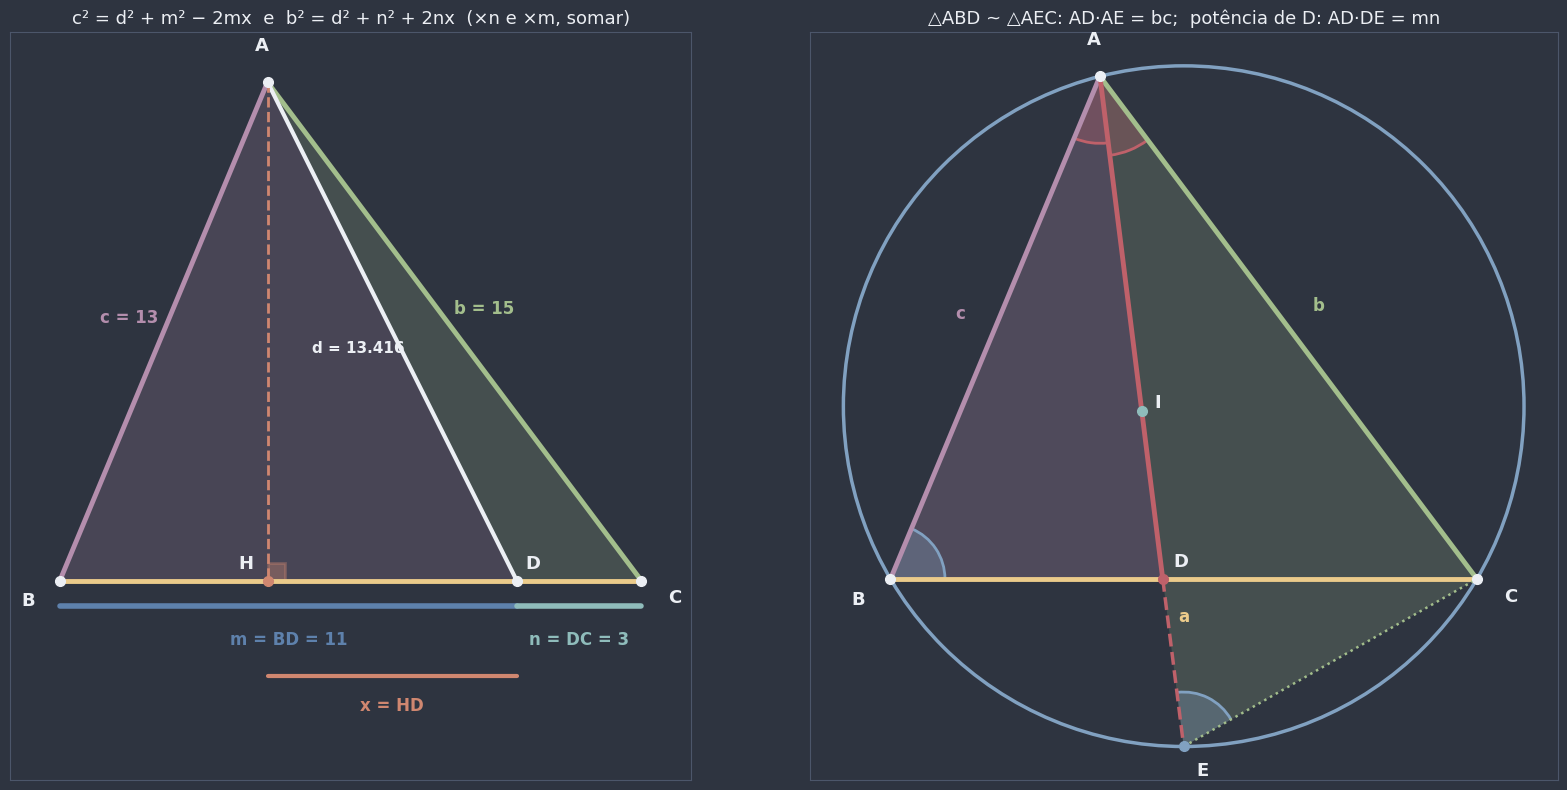

AD·AE = 195 = bc = 195;   AD·DE = 48.75 = mn = 48.75;   AD² = 146.25 = bc − mn = 146.25


In [15]:
fig, (ax_s, ax_p) = plt.subplots(1, 2, figsize=(17, 8))
fig.patch.set_facecolor(NORD_FUNDO)
a, b, c = 14, 15, 13
A, B, C = triangulo_por_lados(a, b, c)
H = pe_da_altura(A, B, C)

# Stewart: D qualquer, com BD = m = 11 e DC = n = 3
m_s = 11.0
D = B + m_s / a * (C - B)
ax_s.add_patch(Polygon([A, B, D], closed=True, facecolor=COR_LADO_C, alpha=0.2, edgecolor="none"))
ax_s.add_patch(Polygon([A, D, C], closed=True, facecolor=COR_LADO_B, alpha=0.2, edgecolor="none"))
desenhar_triangulo(ax_s, A, B, C, preencher=False, rotular_a=False)
desenhar_segmento(ax_s, A, D, cor=NORD_TEXTO, largura=3)
desenhar_segmento(ax_s, A, H, cor=COR_ALTURA, largura=2, estilo="--")
desenhar_setor(ax_s, H, 0, 90, raio=0.7, cor=COR_ALTURA)
for P, Q, cor, texto in ((B, D, COR_PARTE_M, "m = BD = 11"), (D, C, COR_PARTE_N, "n = DC = 3")):
    desenhar_segmento(ax_s, P + (0, -0.6), Q + (0, -0.6), cor=cor, largura=4)
    ax_s.text((P[0] + Q[0]) / 2, -1.2, texto, color=cor, fontsize=12, fontweight="bold", ha="center", va="top")
desenhar_segmento(ax_s, H + (0, -2.3), D + (0, -2.3), cor=COR_ALTURA, largura=3)
ax_s.text((H[0] + D[0]) / 2, -2.8, "x = HD", color=COR_ALTURA, fontsize=12, fontweight="bold", ha="center", va="top")
rotular_segmento(ax_s, A, D, f"d = {math.dist(A, D):.3f}", cor=NORD_TEXTO, distancia=0.9, longe_de=C)
desenhar_ponto(ax_s, D, "D", cor=NORD_TEXTO, deslocamento=(0.2, 0.3))
desenhar_ponto(ax_s, H, "H", cor=COR_ALTURA, deslocamento=(-0.7, 0.3))
preparar_eixo(ax_s, [A, B, C, (0, -3.6)], margem=1.2)
ax_s.set_title("c² = d² + m² − 2mx  e  b² = d² + n² + 2nx  (×n e ×m, somar)", color=NORD_TEXTO, fontsize=13)

# Potência de ponto: a bissetriz AD prolongada até E
m_b, n_b = pe_da_bissetriz(a, b, c)
D = B + m_b / a * (C - B)
O = circuncentro(A, B, C)
R = math.dist(O, A)
u = D - A
E = A - 2 * np.dot(A - O, u) / np.dot(u, u) * u  # o outro ponto da reta AD na circunferência
I = incentro(A, B, C)
desenhar_circunferencia(ax_p, O, R, cor=COR_CIRCUNSCRITA)
ax_p.add_patch(Polygon([A, B, D], closed=True, facecolor=COR_LADO_C, alpha=0.25, edgecolor="none"))
ax_p.add_patch(Polygon([A, E, C], closed=True, facecolor=COR_LADO_B, alpha=0.2, edgecolor="none"))
desenhar_triangulo(ax_p, A, B, C, valores=False, preencher=False)
desenhar_segmento(ax_p, A, D, cor=COR_BISSETRIZ, largura=3.5)
desenhar_segmento(ax_p, D, E, cor=COR_BISSETRIZ, largura=2.5, estilo="--")
desenhar_segmento(ax_p, E, C, cor=COR_LADO_B, largura=1.8, estilo=":")
desenhar_arco(ax_p, A, B, D, raio=1.6, cor=COR_BISSETRIZ)
desenhar_arco(ax_p, A, D, C, raio=1.9, cor=COR_BISSETRIZ)
desenhar_arco(ax_p, B, A, C, raio=1.3, cor=COR_SECUNDARIA)
desenhar_arco(ax_p, E, A, C, raio=1.3, cor=COR_SECUNDARIA)
desenhar_ponto(ax_p, D, "D", cor=COR_BISSETRIZ, deslocamento=(0.25, 0.3))
desenhar_ponto(ax_p, E, "E", cor=COR_CIRCUNSCRITA, deslocamento=(0.3, -0.7))
desenhar_ponto(ax_p, I, "I", cor=COR_INSCRITA, deslocamento=(0.3, 0.1))
preparar_eixo(ax_p, [O - (R, R), O + (R, R)], margem=0.8)
ax_p.set_title("△ABD ~ △AEC: AD·AE = bc;  potência de D: AD·DE = mn", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()
AD, AE, DE = math.dist(A, D), math.dist(A, E), math.dist(D, E)
print(f"AD·AE = {AD * AE:.6g} = bc = {b * c};   AD·DE = {AD * DE:.6g} = mn = {m_b * n_b:g};   "
      f"AD² = {AD**2:.6g} = bc − mn = {b * c - m_b * n_b:g}")

🕹️ **Widget interativo — a ceviana deslizante:** escolha o triângulo e mova o ponto $D$ ao longo de $\overline{BC}$ com o slider (`BD/BC` vai de 0, em $B$, até 1, em $C$). O painel mostra $d = AD$ **medido** e **por Stewart**, e confere a igualdade $b^2 m + c^2 n = a(d^2 + mn)$. Os botões **marcar D como** colocam $D$ no **pé da altura**, no **ponto médio** ou no **pé da bissetriz** (e aí o slider é ignorado). As três cevianas de $A$ ficam sempre desenhadas bem fracas, como referência. No triângulo isósceles, o que acontece com as três?

In [16]:
TRIANGULOS_CEVIANAS = {
    "13–14–15 (terreno)": (14.0, 15.0, 13.0),
    "obtuso em A (10, 7, 5)": (10.0, 7.0, 5.0),
    "isósceles (12, 10, 10)": (12.0, 10.0, 10.0),
}


def explorar_cevianas(triangulo: str, modo: str, posicao: float) -> None:
    a, b, c = TRIANGULOS_CEVIANAS[triangulo]
    A, B, C = triangulo_por_lados(a, b, c)
    pes = {"pé da altura": pe_da_altura(A, B, C)[0], "pé da bissetriz": pe_da_bissetriz(a, b, c)[0],
           "ponto médio": a / 2}
    m = posicao * a if modo == "livre" else pes[modo]
    n = a - m
    D = B + m / a * (C - B)
    d_medido, d_stewart = math.dist(A, D), stewart(a, b, c, m)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.25, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_triangulo(ax, A, B, C, tamanho=11, rotular_a=False)
    for nome, cor in (("pé da altura", COR_ALTURA), ("pé da bissetriz", COR_BISSETRIZ), ("ponto médio", COR_MEDIANA)):
        P = B + pes[nome] / a * (C - B)
        desenhar_segmento(ax, A, P, cor=cor, largura=1.5, alpha=0.35, estilo="--")
        ax.plot(*P, "|", color=cor, markersize=14, mew=2.5, zorder=6)
    cor_d = {"livre": NORD_TEXTO, "pé da altura": COR_ALTURA, "pé da bissetriz": COR_BISSETRIZ,
             "ponto médio": COR_MEDIANA}[modo]
    desenhar_segmento(ax, A, D, cor=cor_d, largura=3.5)
    for P, Q, cor, texto in ((B, D, COR_PARTE_M, f"m = {m:.2f}"), (D, C, COR_PARTE_N, f"n = {n:.2f}")):
        if math.dist(P, Q) > 1e-9:
            desenhar_segmento(ax, P + (0, -0.06 * a), Q + (0, -0.06 * a), cor=cor, largura=4)
            ax.text((P[0] + Q[0]) / 2, -0.1 * a, texto, color=cor, fontsize=11, fontweight="bold", ha="center",
                    va="top")
    desenhar_ponto(ax, D, "D", cor=cor_d, deslocamento=(0.15, 0.25))
    preparar_eixo(ax, [A, B, C, (0, -0.2 * a)], margem=0.08 * a)
    ax.set_title(f"{triangulo}:  D = {modo}", color=NORD_TEXTO, fontsize=13)

    h, t, med = A[1], bissetriz(a, b, c), mediana(a, b, c)
    itens = [
        (f"d medido = {d_medido:.4f}   d por Stewart = {d_stewart:.4f}", iguais(d_medido, d_stewart)),
        (f"b²·m + c²·n = {b**2 * m + c**2 * n:.3f}", True),
        (f"a·(d² + m·n) = {a * (d_stewart**2 + m * n):.3f}", iguais(b**2 * m + c**2 * n, a * (d_stewart**2 + m * n))),
        (f"altura h_a = {h:.4f}", True),
        (f"bissetriz t_a = {t:.4f}   (t_a² = bc − mn com o pé dela)", True),
        (f"mediana m_a = {med:.4f}", True),
        (f"ordem: h_a ≤ t_a ≤ m_a  →  {h:.3f} ≤ {t:.3f} ≤ {med:.3f}", h <= t + 1e-9 <= med + 2e-9),
    ]
    escrever_checklist(ax_lista, itens, f"a = {a:g}, b = {b:g}, c = {c:g}")
    plt.tight_layout()
    plt.show()


controles_cevianas = {
    "triangulo": widgets.Dropdown(options=list(TRIANGULOS_CEVIANAS), description="triângulo:"),
    "modo": widgets.ToggleButtons(options=["livre", "pé da altura", "ponto médio", "pé da bissetriz"],
                                  description="marcar D como:"),
    "posicao": widgets.FloatSlider(value=0.7, min=0.0, max=1.0, step=0.02, description="BD/BC:"),
}
display(widgets.VBox(list(controles_cevianas.values())),
        widgets.interactive_output(explorar_cevianas, controles_cevianas))

Output()

No isósceles com $b = c$, as três cevianas de $A$ **coincidem**: é o fato de [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) e 0410a, agora como o caso de igualdade da ordem altura ≤ bissetriz ≤ mediana. No obtuso em $A$, a bissetriz fica bem no meio das outras duas, mas a ordem continua.

🎯 **Aplicação prática — design, arquitetura e estruturas:** num origami, o vinco que divide um ângulo ao meio é uma bissetriz, e o comprimento dela sai de $t_a^2 = bc - mn$ sem medir ângulo nenhum. Em estruturas, uma **escora** que liga o topo de uma tesoura a um ponto da base é uma ceviana: Stewart dá o comprimento da peça para qualquer posição do apoio, só com os lados da tesoura e a distância do apoio a uma das pontas.

⚠️ **Erro comum: trocar $m$ e $n$ em Stewart.** O $b^2$ multiplica a parte $BD = m$, que fica **junto de $B$**; o $c^2$ multiplica $DC = n$, junto de $C$. Regra de bolso: "cada lado é multiplicado pelo segmento **oposto** à sua extremidade" ($b = CA$ termina em $C$ e multiplica o segmento do lado de $B$). E, na dúvida, teste com a mediana ($m = n$) ou com o caso isósceles antes de aplicar.

📖 **Leitura complementar:** [Teorema de Stewart](https://pt.wikipedia.org/wiki/Teorema_de_Stewart) (Wikipédia).

**Pergunta de checagem:** no triângulo de lados 13, 14 e 15, a bissetriz de $A$ (lado oposto $a = 14$) divide $\overline{BC}$ em quais partes? Quanto mede $t_a^2$?

**Pergunta de checagem:** num triângulo isósceles com $b = c$, por que Stewart com $D$ no ponto médio dá o mesmo resultado que Pitágoras?

## 5. Oficina: a calculadora de triângulos

Três lados **determinam** um triângulo (LLL), e agora sabemos calcular **tudo** a partir deles. O mapa de fórmulas, na ordem em que a calculadora trabalha:

| Passo | Elemento | Fórmula | Seção |
|---|---|---|---|
| 1 | existência | cada lado menor que a soma dos outros dois (equivale a $p > a$, $p > b$, $p > c$) | 0404a, 2 |
| 2 | classificação | maior lado $\ell$: $\ell^2 \lessgtr$ soma dos quadrados dos outros dois | 1 |
| 3 | $p$, $S$, $r$, $R$ | $p = \frac{a + b + c}{2}$, $S = \sqrt{p(p - a)(p - b)(p - c)}$, $r = \frac{S}{p}$, $R = \frac{abc}{4S}$ | 2 |
| 4 | alturas | $h_a = \frac{2S}{a}$, $h_b = \frac{2S}{b}$, $h_c = \frac{2S}{c}$ | 1 e 2 |
| 5 | medianas | $m_a = \frac{1}{2}\sqrt{2b^2 + 2c^2 - a^2}$ (e análogas) | 3 |
| 6 | bissetrizes | $t_a = \frac{2}{b + c}\sqrt{bc \cdot p(p - a)}$ (e análogas) | 4 |
| 7 | segmentos tangentes | $p - a$, $p - b$, $p - c$ | 2 |

Duas desigualdades fecham a ficha: **altura ≤ bissetriz ≤ mediana** (do mesmo vértice) e $r \leq \frac{R}{2}$, a **desigualdade de Euler** (Desafio 8). Esta é a "**ficha técnica do triângulo**".

**No código:** `ficha_triangulo(a, b, c)` devolve um dicionário com todos os elementos. Para não acreditar nas fórmulas "por fé", `medir_ficha(A, B, C)` calcula os **mesmos** valores diretamente nas coordenadas, sem nenhuma fórmula das seções 1 a 4: alturas como distâncias de ponto a reta, medianas como distâncias a pontos médios, bissetrizes como cruzamentos de retas, $R$ pelo cruzamento das mediatrizes e $r$ pela distância do incentro a um lado. Um `assert` compara as duas fichas em vários triângulos.

In [17]:
def ficha_triangulo(a: float, b: float, c: float) -> dict:
    """Ficha técnica do triângulo de lados a, b, c: todos os elementos calculados só pelos lados."""
    if not existe_triangulo(a, b, c):
        return {"existe": False, "classificação": "não forma triângulo"}
    S = area_herao(a, b, c)
    return {
        "existe": True,
        "classificação": classifica_por_lados(a, b, c),
        "perímetro": a + b + c,
        "p": semiperimetro(a, b, c),
        "S": S,
        "r": raio_inscrito(a, b, c),
        "R": raio_circunscrito(a, b, c),
        "h_a": 2 * S / a, "h_b": 2 * S / b, "h_c": 2 * S / c,
        "m_a": mediana(a, b, c, "a"), "m_b": mediana(a, b, c, "b"), "m_c": mediana(a, b, c, "c"),
        "t_a": bissetriz(a, b, c, "a"), "t_b": bissetriz(a, b, c, "b"), "t_c": bissetriz(a, b, c, "c"),
        "tangentes": segmentos_tangentes(a, b, c),
    }


def pe_bissetriz_medido(V, P, Q) -> np.ndarray:
    """Pé da bissetriz do ângulo de vértice V no lado PQ, por coordenadas: a reta que sai de V na direção da soma
    dos vetores unitários VP e VQ cruza a reta PQ."""
    V, P, Q = (np.asarray(X, dtype=float) for X in (V, P, Q))
    u = (P - V) / math.dist(V, P) + (Q - V) / math.dist(V, Q)
    return cruzamento(V, direcao_de(V, V + u), P, direcao_de(P, Q))


def medir_ficha(A, B, C) -> dict:
    """Os mesmos elementos de `ficha_triangulo`, medidos DIRETAMENTE nas coordenadas (sem as fórmulas)."""
    O, I = circuncentro(A, B, C), incentro(A, B, C)
    a, b, c = lados((A, B, C))
    return {
        "perímetro": a + b + c,
        "S": a * distancia_ponto_reta(A, B, C) / 2,
        "r": distancia_ponto_reta(I, B, C),
        "R": math.dist(O, A),
        "h_a": distancia_ponto_reta(A, B, C), "h_b": distancia_ponto_reta(B, C, A),
        "h_c": distancia_ponto_reta(C, A, B),
        "m_a": math.dist(A, ponto_medio(B, C)), "m_b": math.dist(B, ponto_medio(C, A)),
        "m_c": math.dist(C, ponto_medio(A, B)),
        "t_a": math.dist(A, pe_bissetriz_medido(A, B, C)), "t_b": math.dist(B, pe_bissetriz_medido(B, C, A)),
        "t_c": math.dist(C, pe_bissetriz_medido(C, A, B)),
        "tangentes": (math.dist(A, pe_da_altura(I, A, B)), math.dist(B, pe_da_altura(I, B, C)),
                      math.dist(C, pe_da_altura(I, C, A))),
    }


# A ficha do terreno, ao lado da medição direta
ficha, medida = ficha_triangulo(14, 15, 13), medir_ficha(*triangulo_por_lados(14, 15, 13))
linhas = []
for chave, valor in ficha.items():
    if chave in medida:
        texto = ", ".join(f"{v:.4g}" for v in valor) if isinstance(valor, tuple) else f"{valor:.6g}"
        ok = np.allclose(valor, medida[chave])
    else:
        texto, ok = str(valor), True
    linhas.append({"elemento": chave, "ficha (fórmulas)": texto, "confere com a medição?": "✅" if ok else "❌"})
display(pd.DataFrame(linhas))

# Auto-verificação em triângulos de todo tipo, mais 300 sorteados
testes = [(6, 6, 6), (6, 5, 5), (5, 4, 3), (7, 5, 4), (10, 7, 5), (2, 9, 10)]
gerador = np.random.default_rng(5)
while len(testes) < 306:
    candidato = tuple(gerador.uniform(1, 20, size=3))
    if existe_triangulo(*candidato) and area_herao(*candidato) > 0.5:
        testes.append(candidato)
for lados_t in testes:
    ficha, medida = ficha_triangulo(*lados_t), medir_ficha(*triangulo_por_lados(*lados_t))
    for chave in medida:
        assert np.allclose(ficha[chave], medida[chave]), (lados_t, chave)
print(f"fichas conferidas por coordenadas em {len(testes)} triângulos ✅")
print("ficha de 2, 3, 7:", ficha_triangulo(2, 3, 7))

,elemento,ficha (fórmulas),confere com a medição?
0,existe,True,✅
1,classificação,acutângulo,✅
2,perímetro,42,✅
3,p,21.0,✅
4,S,84,✅
5,r,4,✅
6,R,8.125,✅
7,h_a,12,✅
8,h_b,11.2,✅
9,h_c,12.9231,✅


fichas conferidas por coordenadas em 306 triângulos ✅
ficha de 2, 3, 7: {'existe': False, 'classificação': 'não forma triângulo'}


As 15 medidas do terreno conferem uma a uma com a medição direta, e o mesmo vale para os outros 305 triângulos (equilátero, isósceles, retângulo, obtusângulos e sorteados). Para o trio 2, 3, 7, a ficha só diz que o triângulo não existe.

🕹️ **Widget interativo — a calculadora de triângulos:** escolha um triângulo pronto no seletor (equilátero, isósceles, 13–14–15, retângulo 3–4–5, obtuso 4–5–7) ou "personalizado" para usar os três sliders. A figura mostra o triângulo com as três cevianas de $A$ (altura, bissetriz e mediana), as circunferências inscrita e circunscrita e os centros; a tabela embaixo é a ficha completa. Marque a caixa **mostrar a ordem** para ver, em barras, altura ≤ bissetriz ≤ mediana nos três vértices.

In [18]:
PRESETS = {
    "personalizado": None,
    "equilátero (6, 6, 6)": (6.0, 6.0, 6.0),
    "isósceles (6, 5, 5)": (6.0, 5.0, 5.0),
    "13–14–15": (14.0, 15.0, 13.0),
    "retângulo 3–4–5": (5.0, 4.0, 3.0),
    "obtuso 4–5–7": (7.0, 5.0, 4.0),
}


def desenhar_ficha(ax, a: float, b: float, c: float) -> None:
    """Desenha o triângulo com as cevianas de A, as circunferências inscrita e circunscrita e os centros."""
    A, B, C = triangulo_por_lados(a, b, c)
    I, O = incentro(A, B, C), circuncentro(A, B, C)
    ficha = ficha_triangulo(a, b, c)
    H, D, M = pe_da_altura(A, B, C), pe_bissetriz_medido(A, B, C), ponto_medio(B, C)
    escala = max(a, b, c)
    desenhar_triangulo(ax, A, B, C, tamanho=11)
    if H[0] > C[0] or H[0] < B[0]:  # o pé da altura fora do lado: prolongamento pontilhado
        desenhar_segmento(ax, C if H[0] > C[0] else B, H, cor=NORD_TEXTO_SEC, largura=1.5, estilo=":")
    for P, cor in ((H, COR_ALTURA), (D, COR_BISSETRIZ), (M, COR_MEDIANA)):
        desenhar_segmento(ax, A, P, cor=cor, largura=2.2)
        desenhar_ponto(ax, P, cor=cor)
    desenhar_circunferencia(ax, I, ficha["r"], cor=COR_INSCRITA, largura=2)
    desenhar_ponto(ax, I, "I", cor=COR_INSCRITA)
    pontos = [A, B, C, H]
    if ficha["R"] < 2.5 * escala:
        desenhar_circunferencia(ax, O, ficha["R"], cor=COR_CIRCUNSCRITA, largura=2)
        desenhar_ponto(ax, O, "O", cor=COR_CIRCUNSCRITA)
        pontos += [O - (ficha["R"], ficha["R"]), O + (ficha["R"], ficha["R"])]
    preparar_eixo(ax, pontos, margem=0.08 * escala)


def calculadora(preset: str, a: float, b: float, c: float, ordem: bool) -> None:
    if PRESETS[preset] is not None:
        a, b, c = PRESETS[preset]
    ficha = ficha_triangulo(a, b, c)
    if not ficha["existe"]:
        print(f"a = {a:g}, b = {b:g}, c = {c:g}: NÃO forma triângulo (o maior lado é maior ou igual à soma dos "
              "outros dois).")
        return
    colunas = 2 if ordem else 1
    fig, eixos = plt.subplots(1, colunas, figsize=(8 * colunas, 6.6), squeeze=False)
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_ficha(eixos[0, 0], a, b, c)
    eixos[0, 0].set_title(f"a = {a:g}, b = {b:g}, c = {c:g}: {ficha['classificação']}", color=NORD_TEXTO, fontsize=13)
    if ordem:
        ax = eixos[0, 1]
        estilizar_eixo(ax)
        x = np.arange(3)
        for k, (letra, cor, nome) in enumerate((("h", COR_ALTURA, "altura"), ("t", COR_BISSETRIZ, "bissetriz"),
                                                 ("m", COR_MEDIANA, "mediana"))):
            ax.bar(x + (k - 1) * 0.27, [ficha[f"{letra}_{v}"] for v in "abc"], width=0.27, color=cor, label=nome)
        ax.set_xticks(x, ["de A", "de B", "de C"], color=NORD_TEXTO)
        ax.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO)
        ax.set_title("altura ≤ bissetriz ≤ mediana, em cada vértice", color=NORD_TEXTO, fontsize=13)
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame([
        {"elemento": "perímetro, p, S", "valores": f"{ficha['perímetro']:.4g}, {ficha['p']:.4g}, {ficha['S']:.4g}"},
        {"elemento": "r, R (e R ≥ 2r?)", "valores": f"{ficha['r']:.4g}, {ficha['R']:.4g} ({ficha['R'] >= 2 * ficha['r'] - 1e-9})"},
        {"elemento": "alturas h_a, h_b, h_c", "valores": ", ".join(f"{ficha[f'h_{v}']:.4g}" for v in "abc")},
        {"elemento": "medianas m_a, m_b, m_c", "valores": ", ".join(f"{ficha[f'm_{v}']:.4g}" for v in "abc")},
        {"elemento": "bissetrizes t_a, t_b, t_c", "valores": ", ".join(f"{ficha[f't_{v}']:.4g}" for v in "abc")},
        {"elemento": "tangentes p − a, p − b, p − c", "valores": ", ".join(f"{v:.4g}" for v in ficha["tangentes"])},
    ]))


controles_calculadora = {
    "preset": widgets.Dropdown(options=list(PRESETS), value="13–14–15", description="triângulo:"),
    "a": widgets.FloatSlider(value=8, min=1, max=15, step=0.5, description="a:"),
    "b": widgets.FloatSlider(value=6, min=1, max=15, step=0.5, description="b:"),
    "c": widgets.FloatSlider(value=5, min=1, max=15, step=0.5, description="c:"),
    "ordem": widgets.Checkbox(value=True, description="mostrar a ordem altura ≤ bissetriz ≤ mediana"),
}
display(widgets.VBox(list(controles_calculadora.values())),
        widgets.interactive_output(calculadora, controles_calculadora))

Output()

Com "personalizado", os sliders mandam; com os outros, eles são ignorados. No equilátero, as nove cevianas têm o mesmo tamanho e os centros coincidem ($R = 2r$, o caso de igualdade de Euler); no retângulo 3–4–5, o circuncentro cai no meio da hipotenusa; no obtuso 4–5–7 (obtuso em $A$), ele cai **fora** do triângulo, como em 0410a.

🎯 **Aplicação prática — computação gráfica:** todo modelo 3D de um jogo ou de um filme é uma malha de **triângulos** (às vezes milhões). Calcular a área de cada um (para iluminação e texturas), o baricentro (para física e colisões) e a qualidade da malha (triângulos "agulha" causam defeitos visuais, e a razão $\frac{r}{R}$, que vale $\frac{1}{2}$ no equilátero e cai perto de 0 nos achatados, é uma medida clássica dessa qualidade) é exatamente o que a calculadora faz, em escala industrial.

**Pergunta de checagem:** quais dados da ficha **precisam** que o triângulo seja acutângulo para valer? Algum depende de ele ser retângulo?

📎 **Conexão — a Trigonometria e a unificação:** tudo o que fizemos usou só **comprimentos**: nenhum seno, nenhum cosseno. Quando você souber medir ângulos com seno, cosseno e tangente, vai conseguir o caminho inverso, achar lados a partir de ângulos, com a **Lei dos Cossenos** (a relação da seção 1 com $n = b \cos \hat{C}$) e a **Lei dos Senos** ($2R = \frac{a}{\operatorname{sen} \hat{A}}$, uma prima da relação $2R \cdot h_a = bc$ da seção 2), em [`0510a_triangulos_quaisquer.ipynb`](../05_trigonometria/0510a_triangulos_quaisquer.ipynb). A fórmula da seção 1 vai reaparecer com outra cara.

E repare na **cadeia** deste notebook: uma **única** ideia, $c^2 = a^2 + b^2 \mp 2an$ (Pitágoras com a projeção), está por trás de **tudo**. Ela deu a altura; a altura deu Herão; Herão deu $r$ e $R$; aplicada duas vezes em triângulos com ângulos suplementares, deu a mediana; com o truque de multiplicar por $n$ e $m$, deu Stewart; e Stewart, com o teorema da bissetriz de 0414a, deu a bissetriz.

## Resumo — cheat sheet

**Notação fixa:** lados $a = BC$, $b = CA$, $c = AB$ (opostos a $A$, $B$, $C$); $p = \frac{a + b + c}{2}$; projeções $m = BH$ e $n = HC$ (com sinal); $h_a$, $m_a$, $t_a$ altura, mediana e bissetriz de $A$; $S$ área; $r$ e $R$ raios das circunferências inscrita e circunscrita.

| Conceito | Ideia-chave |
|---|---|
| **Pitágoras generalizado** | $c^2 = a^2 + b^2 - 2an$ ($\hat{C}$ agudo) e $c^2 = a^2 + b^2 + 2a\lvert n \rvert$ ($\hat{C}$ obtuso); com sinal: $n = \frac{a^2 + b^2 - c^2}{2a}$ |
| **Classificação** (maior lado $\ell$) | $\ell^2 <$ soma dos outros dois ao quadrado: acutângulo; $=$: retângulo; $>$: obtusângulo (agora **demonstrada**) |
| **Altura** | $h_a = \sqrt{b^2 - n^2} = \frac{2S}{a}$ |
| **Herão** | $S = \sqrt{p(p - a)(p - b)(p - c)}$; existe triângulo $\iff$ os quatro fatores são positivos |
| **Segmentos tangentes** | $p - a$, $p - b$, $p - c$ (de $A$, $B$, $C$) |
| **Raios** | $r = \frac{S}{p}$ (pois $S = p \cdot r$); $R = \frac{abc}{4S}$ (pois $2R \cdot h_a = bc$) |
| **Mediana** | $m_a = \frac{1}{2}\sqrt{2b^2 + 2c^2 - a^2}$; $\sum m^2 = \frac{3}{4}\sum \text{lados}^2$; $GA = \frac{2}{3} m_a$ |
| **Paralelogramo** | $d_1^2 + d_2^2 = 2x^2 + 2y^2$ |
| **Triângulo medial** | lados $\frac{a}{2}$, $\frac{b}{2}$, $\frac{c}{2}$ (base média), semelhante na razão $1 : 2$, mesmo baricentro |
| **Stewart** | $b^2 \cdot m + c^2 \cdot n = a\left(d^2 + m \cdot n\right)$ ($m = BD$, $n = DC$) |
| **Bissetriz** | $m = \frac{ac}{b + c}$, $n = \frac{ab}{b + c}$; $t_a^2 = bc - mn$; $t_a = \frac{2}{b + c}\sqrt{bc \cdot p(p - a)}$ |
| **Incentro** | $\frac{AI}{ID} = \frac{b + c}{a}$ |
| **Ordem** | altura ≤ bissetriz ≤ mediana (do mesmo vértice); $R \geq 2r$ (Euler) |

**A cadeia:** Pitágoras (0416a) → Pitágoras com projeção (seção 1) → altura, área e raios (seção 2) → medianas e cevianas (seções 3 e 4) → bissetriz. Uma única ideia, aplicada de várias formas.

As figuras abaixo repetem as cores do notebook.

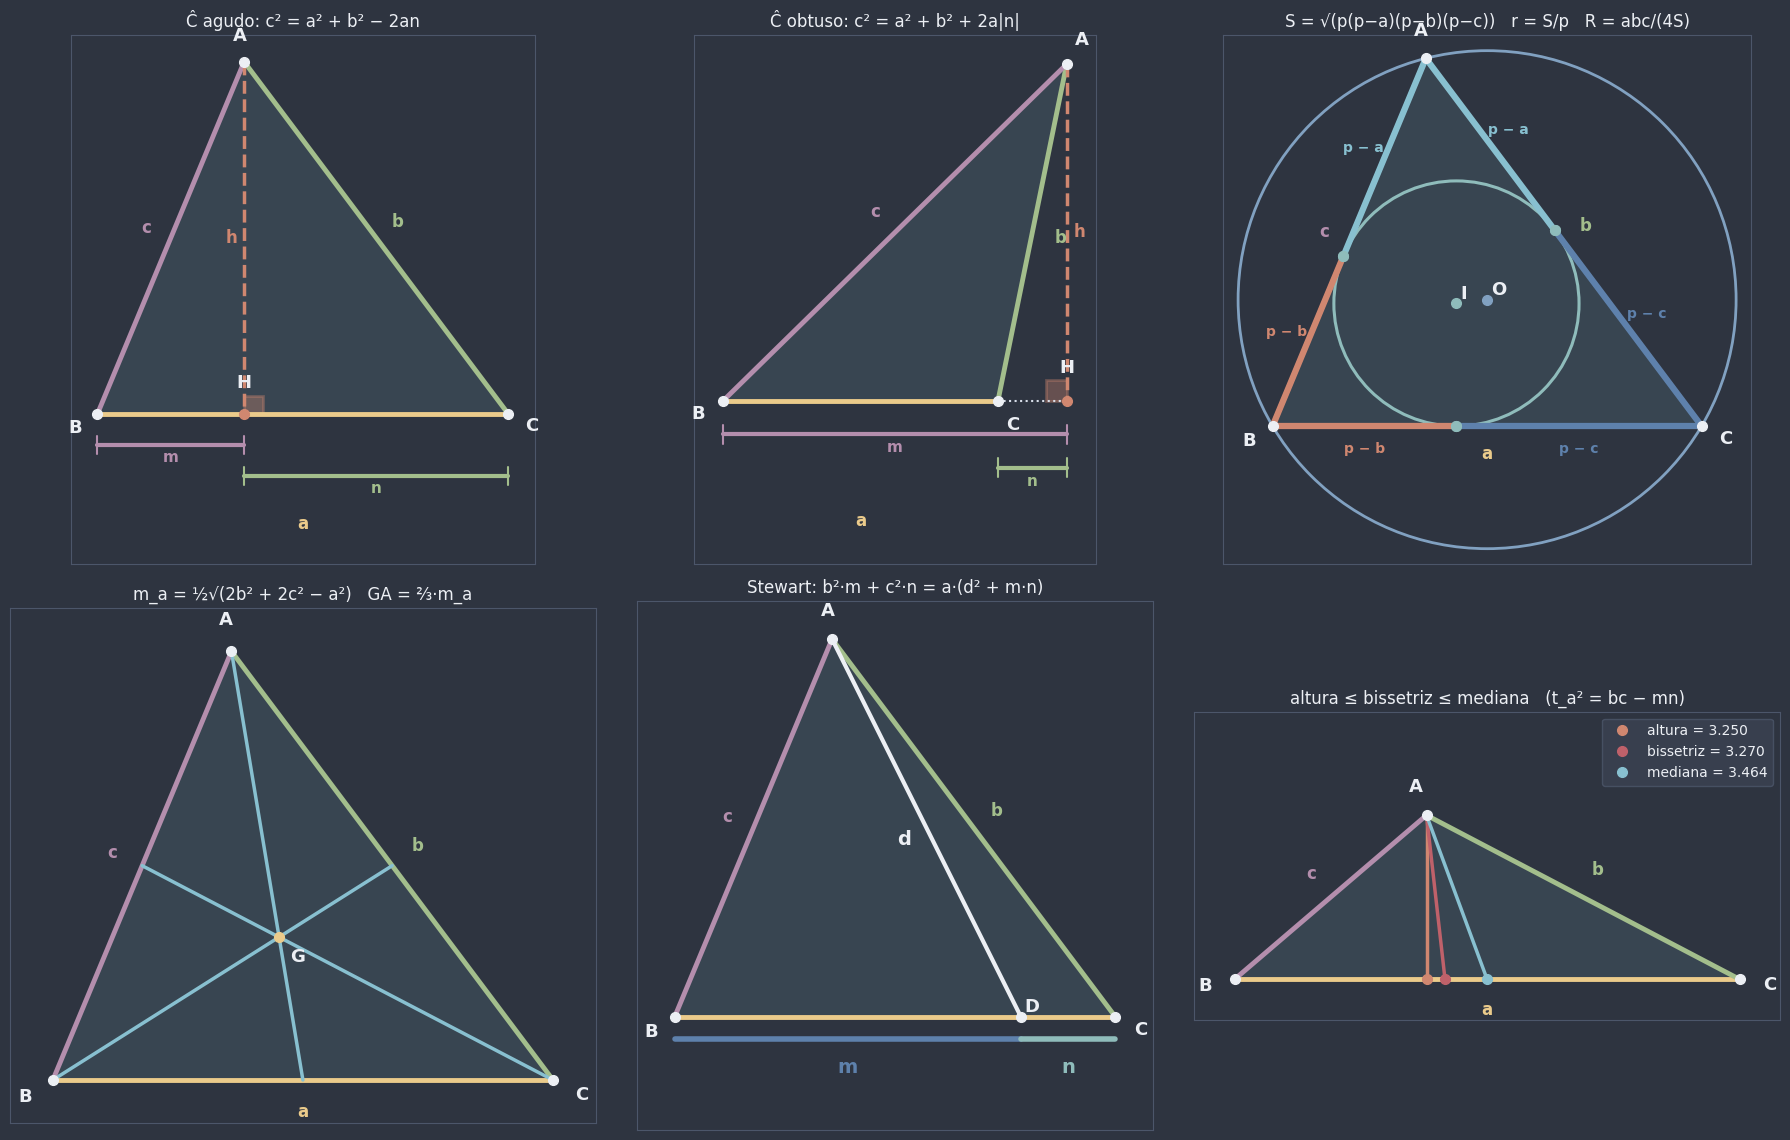

In [19]:
# Esta célula usa as ferramentas construídas ao longo do notebook (desenho, projeção, tangentes e bissetriz)
fig, eixos = plt.subplots(2, 3, figsize=(18, 11.5))
fig.patch.set_facecolor(NORD_FUNDO)

# Pitágoras generalizado: agudo e obtuso
for ax, (a, b, c), titulo in ((eixos[0, 0], (14, 15, 13), "Ĉ agudo: c² = a² + b² − 2an"),
                              (eixos[0, 1], (4, 5, 7), "Ĉ obtuso: c² = a² + b² + 2a|n|")):
    A, B, C = triangulo_por_lados(a, b, c)
    pontos = desenhar_projecao(ax, A, B, C, valores=False)
    preparar_eixo(ax, pontos, margem=0.06 * max(a, b, c))
    ax.set_title(titulo, color=NORD_TEXTO, fontsize=12)

# Herão e os raios
ax = eixos[0, 2]
A, B, C = triangulo_por_lados(14, 15, 13)
O, I = circuncentro(A, B, C), incentro(A, B, C)
R, r = math.dist(O, A), distancia_ponto_reta(I, B, C)
desenhar_circunferencia(ax, O, R, cor=COR_CIRCUNSCRITA, largura=2)
desenhar_triangulo(ax, A, B, C, valores=False)
desenhar_tangentes(ax, A, B, C, tamanho=10, valores=False)
desenhar_ponto(ax, O, "O", cor=COR_CIRCUNSCRITA)
desenhar_ponto(ax, I, "I", cor=COR_INSCRITA)
preparar_eixo(ax, [O - (R, R), O + (R, R)], margem=0.5)
ax.set_title("S = √(p(p−a)(p−b)(p−c))   r = S/p   R = abc/(4S)", color=NORD_TEXTO, fontsize=12)

# Mediana e baricentro
ax = eixos[1, 0]
desenhar_triangulo(ax, A, B, C, valores=False)
for V, P in ((A, ponto_medio(B, C)), (B, ponto_medio(C, A)), (C, ponto_medio(A, B))):
    desenhar_segmento(ax, V, P, cor=COR_MEDIANA, largura=2.5)
desenhar_ponto(ax, baricentro(A, B, C), "G", cor=COR_AVISO, deslocamento=(0.3, -0.7))
preparar_eixo(ax, [A, B, C], margem=1.2)
ax.set_title("m_a = ½√(2b² + 2c² − a²)   GA = ⅔·m_a", color=NORD_TEXTO, fontsize=12)

# Stewart
ax = eixos[1, 1]
D = np.array([11.0, 0.0])
desenhar_triangulo(ax, A, B, C, valores=False, rotular_a=False)
desenhar_segmento(ax, A, D, cor=NORD_TEXTO, largura=3)
for P, Q, cor, nome in ((B, D, COR_PARTE_M, "m"), (D, C, COR_PARTE_N, "n")):
    desenhar_segmento(ax, P + (0, -0.7), Q + (0, -0.7), cor=cor, largura=4)
    ax.text((P[0] + Q[0]) / 2, -1.3, nome, color=cor, fontsize=14, fontweight="bold", ha="center", va="top")
rotular_segmento(ax, A, D, "d", cor=NORD_TEXTO, distancia=0.8, longe_de=C, tamanho=14)
desenhar_ponto(ax, D, "D", cor=NORD_TEXTO)
preparar_eixo(ax, [A, B, C, (0, -2.4)], margem=1.2)
ax.set_title("Stewart: b²·m + c²·n = a·(d² + m·n)", color=NORD_TEXTO, fontsize=12)

# As três cevianas de A
ax = eixos[1, 2]
A, B, C = triangulo_por_lados(10, 7, 5)
desenhar_triangulo(ax, A, B, C, valores=False)
for P, cor, nome in ((pe_da_altura(A, B, C), COR_ALTURA, "altura"), (pe_bissetriz_medido(A, B, C), COR_BISSETRIZ,
                                                                       "bissetriz"),
                     (ponto_medio(B, C), COR_MEDIANA, "mediana")):
    desenhar_segmento(ax, A, P, cor=cor, largura=2.5)
    ax.plot(*P, "o", color=cor, markersize=7, zorder=6, label=f"{nome} = {math.dist(A, P):.3f}")
ax.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO, loc="upper right")
preparar_eixo(ax, [A, B, C, (10, 4.5)], margem=0.8)
ax.set_title("altura ≤ bissetriz ≤ mediana   (t_a² = bc − mn)", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

## Exercícios

**Básico**
1. Classificação pelos lados, projeção e altura.
2. Herão, raios e segmentos tangentes.
3. Medianas e baricentro.

**Intermediário**

4. A sua própria calculadora: `area_herao`, raios, mediana, bissetriz e ficha, conferidas com coordenadas.
5. Stewart na prática: as três cevianas do terreno e 200 pontos sorteados.
6. Das medianas para os lados.
7. Problemas de dois ou três passos: o triângulo isósceles e a distância entre incentro e circuncentro.

**Desafio**

8. A fórmula de Euler, $d^2 = R^2 - 2Rr$.
9. Herão estável × ingênuo.
10. O maior triângulo com dois lados dados.

Gabarito completo com resolução comentada em [`0417b_triangulos_quaisquer_gabarito.ipynb`](0417b_triangulos_quaisquer_gabarito.ipynb).

### Básico

In [ ]:
# Exercício Básico 1: classificação pelos lados, projeção e altura.
# (a) Para cada trio de lados da lista trios_ex1, guarde em `classificacoes_ex1a` a LISTA (na mesma ordem) das
#     classificações: "acutângulo", "retângulo", "obtusângulo" ou "não forma triângulo".
# (b) No triângulo de lados a = 21, b = 17 e c = 10, guarde a projeção n = HC (com sinal) do lado b sobre o lado a
#     em `n_ex1b` e a projeção m = BH em `m_ex1b`.
# (c) Guarde a altura h_a desse mesmo triângulo em `h_ex1c`.
# (d) No triângulo de lados a = 4, b = 5 e c = 7, guarde a projeção n (COM SINAL) em `n_ex1d`.
trios_ex1 = [(6, 7, 8), (9, 12, 15), (5, 6, 9), (2, 3, 6), (7, 8, 10)]

classificacoes_ex1a = ...
n_ex1b = ...
m_ex1b = ...
h_ex1c = ...
n_ex1d = ...

print(classificacoes_ex1a, n_ex1b, m_ex1b, h_ex1c, n_ex1d)

In [ ]:
# Verificação
assert classificacoes_ex1a is not ... and list(classificacoes_ex1a) == [
    "acutângulo", "retângulo", "obtusângulo", "não forma triângulo", "acutângulo"], (
    "Tente de novo, revise: teste a desigualdade triangular e compare o quadrado do MAIOR lado com a soma dos "
    "quadrados dos outros dois (seção 1 - Pitágoras além do ângulo reto)."
)
assert n_ex1b is not ... and math.isclose(n_ex1b, 15) and m_ex1b is not ... and math.isclose(m_ex1b, 6), (
    "Tente de novo, revise: n = (a² + b² − c²)/(2a) e m = a − n (seção 1 - Pitágoras além do ângulo reto)."
)
assert h_ex1c is not ... and math.isclose(h_ex1c, 8), (
    "Tente de novo, revise: h_a = √(b² − n²), Pitágoras no triângulo AHC (seção 1 - Pitágoras além do ângulo reto)."
)
assert n_ex1d is not ... and math.isclose(n_ex1d, -1), (
    "Tente de novo, revise: com o ângulo C obtuso, n = (a² + b² − c²)/(2a) sai NEGATIVO (seção 1 - Pitágoras além do ângulo reto)."
)
print("Certo!")

In [ ]:
# Exercício Básico 2: Herão, raios e segmentos tangentes. O triângulo tem lados a = 9, b = 10 e c = 17.
# (a) Guarde a área (fórmula de Herão) em `S_ex2a`.
# (b) Guarde o raio da circunferência inscrita em `r_ex2b` e o da circunscrita em `R_ex2b`.
# (c) Guarde em `tangentes_ex2c` a tupla (p − a, p − b, p − c) dos segmentos tangentes traçados de A, B e C.
# (d) Para cada trio da lista trios_ex2, guarde em `existem_ex2d` a LISTA de True/False dizendo se ele forma
#     triângulo. Use o radicando de Herão, p(p − a)(p − b)(p − c), e não a desigualdade triangular diretamente.
trios_ex2 = [(2, 3, 7), (3, 4, 5), (1, 1, 2), (5, 5, 9)]

S_ex2a = ...
r_ex2b = ...
R_ex2b = ...
tangentes_ex2c = ...
existem_ex2d = ...

print(S_ex2a, r_ex2b, R_ex2b, tangentes_ex2c, existem_ex2d)

In [ ]:
# Verificação
assert S_ex2a is not ... and math.isclose(S_ex2a, 36), (
    "Tente de novo, revise: p = 18 e S = √(18 · 9 · 8 · 1) (seção 2 - Altura, área e a fórmula de Herão)."
)
assert r_ex2b is not ... and math.isclose(r_ex2b, 2) and R_ex2b is not ... and math.isclose(R_ex2b, 10.625), (
    "Tente de novo, revise: r = S/p e R = abc/(4S) (seção 2 - Altura, área e a fórmula de Herão)."
)
assert tangentes_ex2c is not ... and np.allclose(tangentes_ex2c, (9, 8, 1)), (
    "Tente de novo, revise: os segmentos tangentes de A, B e C são p − a, p − b e p − c (seção 2 - Altura, área e a fórmula de Herão)."
)
assert existem_ex2d is not ... and [bool(x) for x in existem_ex2d] == [False, True, False, True], (
    "Tente de novo, revise: o triângulo existe só se o radicando for POSITIVO; zero é o triângulo achatado (seção 2 - Altura, área e a fórmula de Herão)."
)
print("Certo!")

In [ ]:
# Exercício Básico 3: medianas e baricentro.
# (a) No triângulo retângulo de lados 6, 8 e 10, guarde em `mediana_hip_ex3a` a mediana relativa à hipotenusa,
#     calculada pela FÓRMULA do teorema da mediana.
# (b) No triângulo de lados a = 8, b = 7 e c = 9, guarde a tupla (m_a, m_b, m_c) em `medianas_ex3b`.
# (c) Guarde em `GA_ex3c` a distância do vértice A ao baricentro desse triângulo.
# (d) Guarde em `soma_ex3d` a soma m_a² + m_b² + m_c², usando o corolário 2 (sem calcular as medianas).
mediana_hip_ex3a = ...
medianas_ex3b = ...
GA_ex3c = ...
soma_ex3d = ...

print(mediana_hip_ex3a, medianas_ex3b, GA_ex3c, soma_ex3d)

In [ ]:
# Verificação
assert mediana_hip_ex3a is not ... and math.isclose(mediana_hip_ex3a, 5), (
    "Tente de novo, revise: m_a² = (2b² + 2c² − a²)/4 com a = 10, a hipotenusa (seção 3 - O teorema da mediana)."
)
assert medianas_ex3b is not ... and np.allclose(medianas_ex3b, (7, math.sqrt(241) / 2, math.sqrt(145) / 2)), (
    "Tente de novo, revise: em cada mediana, o lado com sinal MENOS é aquele que ela corta ao meio (seção 3 - O teorema da mediana)."
)
assert GA_ex3c is not ... and math.isclose(GA_ex3c, 14 / 3), (
    "Tente de novo, revise: o baricentro está a ⅔ da mediana, a partir do vértice (seção 3 - O teorema da mediana)."
)
assert soma_ex3d is not ... and math.isclose(soma_ex3d, 145.5), (
    "Tente de novo, revise: m_a² + m_b² + m_c² = ¾·(a² + b² + c²) (seção 3 - O teorema da mediana)."
)
print("Certo!")

### Intermediário

In [ ]:
# Exercício Intermediário 4: a sua própria calculadora.
# Complete as funções abaixo SEM usar as do notebook (area_herao, raio_inscrito, raio_circunscrito, mediana,
# bissetriz, ficha_triangulo). Pode usar math.sqrt e existe_triangulo.
# (a) area_herao_ex4(a, b, c): a fórmula de Herão. Se as medidas não formarem triângulo, levante um ValueError
#     (raise ValueError("...")) com uma mensagem clara.
# (b) raio_inscrito_ex4(a, b, c) e raio_circunscrito_ex4(a, b, c).
# (c) mediana_ex4(a, b, c) e bissetriz_ex4(a, b, c): a mediana e a bissetriz traçadas de A (relativas ao lado a).
# (d) ficha_triangulo_ex4(a, b, c): um dicionário com as chaves "S", "r", "R", "h_a", "m_a" e "t_a".
# A verificação compara as suas funções com medidas feitas DIRETAMENTE nas coordenadas (medir_ficha) em 300
# triângulos sorteados.
def area_herao_ex4(a: float, b: float, c: float) -> float:
    ...


def raio_inscrito_ex4(a: float, b: float, c: float) -> float:
    ...


def raio_circunscrito_ex4(a: float, b: float, c: float) -> float:
    ...


def mediana_ex4(a: float, b: float, c: float) -> float:
    ...


def bissetriz_ex4(a: float, b: float, c: float) -> float:
    ...


def ficha_triangulo_ex4(a: float, b: float, c: float) -> dict:
    ...


print(area_herao_ex4(14, 15, 13), raio_inscrito_ex4(14, 15, 13), raio_circunscrito_ex4(14, 15, 13),
      mediana_ex4(14, 15, 13), bissetriz_ex4(14, 15, 13), ficha_triangulo_ex4(14, 15, 13))

In [ ]:
# Verificação
funcoes_ex4 = (area_herao_ex4, raio_inscrito_ex4, raio_circunscrito_ex4, mediana_ex4, bissetriz_ex4)
assert all(isinstance(f(14, 15, 13), (int, float)) for f in funcoes_ex4), (
    "Tente de novo, revise: todas as funções devem devolver um número (troque o ... pelo cálculo) (seção 5 - Oficina: a calculadora de triângulos)."
)
assert np.allclose([f(14, 15, 13) for f in funcoes_ex4], (84, 4, 8.125, math.sqrt(148), math.sqrt(146.25))), (
    "Tente de novo, revise: no terreno, S = 84, r = 4, R = 8,125, m_a = √148 e t_a = √146,25 (seção 5 - Oficina: a calculadora de triângulos)."
)
try:
    area_herao_ex4(2, 3, 7)
    levantou_ex4 = False
except ValueError:
    levantou_ex4 = True
assert levantou_ex4, (
    "Tente de novo, revise: area_herao_ex4(2, 3, 7) deve levantar ValueError, pois 7 > 2 + 3 (seção 2 - Altura, área e a fórmula de Herão)."
)
gerador_v4 = np.random.default_rng(44)
for _ in range(300):
    A_v, B_v, C_v = gerador_v4.uniform(-10, 10, size=(3, 2))
    a_v, b_v, c_v = lados((A_v, B_v, C_v))
    if a_v * distancia_ponto_reta(A_v, B_v, C_v) / 2 < 0.5:
        continue
    medida_v = medir_ficha(A_v, B_v, C_v)
    ficha_v = ficha_triangulo_ex4(a_v, b_v, c_v)
    for chave in ("S", "r", "R", "h_a", "m_a", "t_a"):
        assert ficha_v is not None and chave in ficha_v and math.isclose(ficha_v[chave], medida_v[chave],
                                                                         rel_tol=1e-6), (
            f"Tente de novo, revise: a chave '{chave}' da ficha não confere com a medição nas coordenadas; "
            f"h_a = 2S/a, m_a = ½√(2b² + 2c² − a²), t_a = 2√(bc·p(p − a))/(b + c) (seção 5 - Oficina: a calculadora de triângulos)."
        )
print("Certo!")

In [ ]:
# Exercício Intermediário 5: Stewart na prática.
# (a) Complete stewart_ex5(a, b, c, m), que devolve d = AD para o ponto D de BC com BD = m, pelo teorema de
#     Stewart, b²·m + c²·n = a·(d² + m·n). Não use a função stewart do notebook.
# (b) No terreno (a = 14, b = 15, c = 13), use stewart_ex5 para guardar: a altura de A em `d_altura_ex5` (o pé da
#     altura está a 5 de B, seção 1), a mediana de A em `d_mediana_ex5` e a bissetriz de A em `d_bissetriz_ex5`
#     (calcule BD pelo teorema da bissetriz interna).
# (c) Com gerador_ex5 = np.random.default_rng(5), repita 200 vezes, NESTA ORDEM: sorteie os vértices
#     A, B, C = gerador_ex5.uniform(-10, 10, size=(3, 2)) e depois t = gerador_ex5.uniform(0, 1), com
#     D = B + t·(C − B). Pule os triângulos com área menor que 0,5 (use a·distancia_ponto_reta(A, B, C)/2). Guarde
#     em `erro_ex5` a maior diferença |stewart_ex5(a, b, c, BD) − AD| entre os triângulos testados.
gerador_ex5 = np.random.default_rng(5)


def stewart_ex5(a: float, b: float, c: float, m: float) -> float:
    ...


d_altura_ex5 = ...
d_mediana_ex5 = ...
d_bissetriz_ex5 = ...
erro_ex5 = ...

print(d_altura_ex5, d_mediana_ex5, d_bissetriz_ex5, erro_ex5)

In [ ]:
# Verificação
A_v, B_v, C_v = triangulo_por_lados(10, 7, 5)
for m_v in (0.0, 2.5, 3.0, 7.0, 10.0):
    D_v = B_v + m_v / 10 * (C_v - B_v)
    assert stewart_ex5(10, 7, 5, m_v) is not None and math.isclose(stewart_ex5(10, 7, 5, m_v), math.dist(A_v, D_v)), (
        "Tente de novo, revise: d² = (b²·m + c²·n)/a − m·n, com n = a − m; o b² multiplica a parte do lado de B "
        "(seção 4 - O teorema de Stewart e o comprimento da bissetriz)."
    )
assert d_altura_ex5 is not ... and math.isclose(d_altura_ex5, 12), (
    "Tente de novo, revise: com BD = 5 (o pé da altura), Stewart devolve h_a (seção 4 - O teorema de Stewart e o comprimento da bissetriz)."
)
assert d_mediana_ex5 is not ... and math.isclose(d_mediana_ex5, math.sqrt(148)), (
    "Tente de novo, revise: na mediana, BD = a/2 = 7 (seção 4 - O teorema de Stewart e o comprimento da bissetriz)."
)
assert d_bissetriz_ex5 is not ... and math.isclose(d_bissetriz_ex5, math.sqrt(146.25)), (
    "Tente de novo, revise: na bissetriz, BD/DC = c/b, então BD = ac/(b + c) = 6,5 (seção 4 - O teorema de Stewart e o comprimento da bissetriz)."
)
assert erro_ex5 is not ... and 0 <= erro_ex5 < 1e-6, (
    "Tente de novo, revise: BD = t·a; compare stewart_ex5(a, b, c, t·a) com math.dist(A, D) (seção 4 - O teorema de Stewart e o comprimento da bissetriz)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 6: das medianas para os lados.
# As três fórmulas da mediana formam um sistema linear nas incógnitas a², b² e c² (módulo 03). Resolvendo-o,
# a = ⅔·√(2·m_b² + 2·m_c² − m_a²), e analogamente para b e c (repare: é a fórmula da mediana "ao contrário").
# (a) Complete lados_por_medianas_ex6(ma, mb, mc), que devolve a tupla (a, b, c).
# (b) Guarde em `lados_terreno_ex6` o resultado para as medianas do terreno: m_a² = 148, m_b² = 126,25 e
#     m_c² = 168,25 (passe as medianas, e não os quadrados!).
# (c) Guarde em `confere_ex6` True se, para os lados (8, 7, 9), calcular as medianas com a função `medianas` do
#     notebook e voltar com lados_por_medianas_ex6 devolve de novo (8, 7, 9) (use np.allclose).
def lados_por_medianas_ex6(ma: float, mb: float, mc: float) -> tuple[float, float, float]:
    ...


lados_terreno_ex6 = ...
confere_ex6 = ...

print(lados_terreno_ex6, confere_ex6)

In [ ]:
# Verificação
assert lados_terreno_ex6 is not ... and np.allclose(lados_terreno_ex6, (14, 15, 13)), (
    "Tente de novo, revise: a = ⅔·√(2m_b² + 2m_c² − m_a²); as medianas são √148, √126,25 e √168,25 (seção 3 - O teorema da mediana)."
)
assert confere_ex6 is not ... and bool(confere_ex6), (
    "Tente de novo, revise: lados → medianas → lados deve voltar ao começo (seção 3 - O teorema da mediana)."
)
gerador_v6 = np.random.default_rng(66)
for _ in range(100):
    lados_v = gerador_v6.uniform(1, 10, size=3)
    if existe_triangulo(*lados_v):
        assert np.allclose(lados_por_medianas_ex6(*medianas(*lados_v)), lados_v), (
            "Tente de novo, revise: confira as três fórmulas; em cada uma, a mediana do PRÓPRIO lado entra com "
            f"sinal menos (seção 3 - O teorema da mediana)."
        )
print("Certo!")

In [ ]:
# Exercício Intermediário 7: problemas de dois ou três passos.
# (a) Um triângulo isósceles tem lados 10, 10 e 12 (a base é 12). Guarde a altura relativa à base em
#     `altura_ex7`, a área em `S_ex7`, o raio da circunferência inscrita em `r_ex7` e o da circunscrita em `R_ex7`.
# (b) No terreno 13–14–15, guarde em `d_IO_ex7` a distância entre o incentro e o circuncentro. Use as ferramentas
#     de coordenadas do notebook (triangulo_por_lados, incentro, circuncentro).
altura_ex7 = ...
S_ex7 = ...
r_ex7 = ...
R_ex7 = ...
d_IO_ex7 = ...

print(altura_ex7, S_ex7, r_ex7, R_ex7, d_IO_ex7)

In [ ]:
# Verificação
assert altura_ex7 is not ... and math.isclose(altura_ex7, 8) and S_ex7 is not ... and math.isclose(S_ex7, 48), (
    "Tente de novo, revise: no isósceles, a altura cai no meio da base: √(10² − 6²); ou use Herão com p = 16 (seção 2 - Altura, área e a fórmula de Herão)."
)
assert r_ex7 is not ... and math.isclose(r_ex7, 3) and R_ex7 is not ... and math.isclose(R_ex7, 6.25), (
    "Tente de novo, revise: r = S/p e R = abc/(4S) (seção 2 - Altura, área e a fórmula de Herão)."
)
assert d_IO_ex7 is not ... and math.isclose(d_IO_ex7, math.sqrt(1.015625)), (
    "Tente de novo, revise: monte o triângulo com triangulo_por_lados(14, 15, 13) e meça math.dist(I, O) (seção 5 - Oficina: a calculadora de triângulos)."
)
print("Certo!")

### Desafio

In [ ]:
# Exercício Desafio 8: a fórmula de Euler. Para todo triângulo, a distância d entre o incentro e o circuncentro
# satisfaz d² = R² − 2·R·r. Consequência: R ≥ 2r (desigualdade de Euler), com igualdade só no equilátero.
# (a) Com gerador_ex8 = np.random.default_rng(8), sorteie 500 triângulos (A, B, C = gerador_ex8.uniform(-10, 10,
#     size=(3, 2)); pule os de área menor que 0,5). Para cada um, calcule R e r pelas fórmulas da seção 2 e d pelas
#     coordenadas (incentro e circuncentro). Guarde em `erro_euler_ex8` o maior valor de |d² − (R² − 2Rr)| / R².
# (b) Guarde em `sempre_R_maior_2r_ex8` True se R ≥ 2r valeu em TODOS os triângulos testados.
# (c) Guarde em `d2_terreno_ex8` o valor de d² no terreno 13–14–15 (pelas coordenadas).
# (d) Guarde em `diferenca_equilatero_ex8` o valor de R − 2r no triângulo equilátero de lado 6 (pelas fórmulas).
# (e) Para quem quiser: a prova usa a potência do incentro em relação à circunferência circunscrita (0415a):
#     a bissetriz AI corta a circunscrita em E, e Pot(I) = IA·IE = R² − d². Mostre que IE = EB (o "lema do
#     tridente") e que IA·EB = 2Rr.
gerador_ex8 = np.random.default_rng(8)

erro_euler_ex8 = ...
sempre_R_maior_2r_ex8 = ...
d2_terreno_ex8 = ...
diferenca_equilatero_ex8 = ...

print(erro_euler_ex8, sempre_R_maior_2r_ex8, d2_terreno_ex8, diferenca_equilatero_ex8)

In [ ]:
# Verificação
assert erro_euler_ex8 is not ... and 0 <= erro_euler_ex8 < 1e-8, (
    "Tente de novo, revise: R = abc/(4S), r = S/p e d = math.dist(incentro, circuncentro); guarde o MAIOR erro "
    f"relativo (seção 5 - Oficina: a calculadora de triângulos)."
)
assert sempre_R_maior_2r_ex8 is not ... and bool(sempre_R_maior_2r_ex8), (
    f"Tente de novo, revise: como d² ≥ 0, R² − 2Rr ≥ 0, ou seja, R ≥ 2r (seção 5 - Oficina: a calculadora de triângulos)."
)
assert d2_terreno_ex8 is not ... and math.isclose(d2_terreno_ex8, 1.015625), (
    f"Tente de novo, revise: no terreno, R = 8,125 e r = 4, então d² = 8,125² − 2·8,125·4 (seção 5 - Oficina: a calculadora de triângulos)."
)
assert diferenca_equilatero_ex8 is not ... and math.isclose(diferenca_equilatero_ex8, 0, abs_tol=1e-9), (
    f"Tente de novo, revise: no equilátero, incentro e circuncentro coincidem (d = 0), então R = 2r (seção 2 - Altura, área e a fórmula de Herão)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 9: Herão estável × ingênuo.
# (a) Complete area_kahan_ex9(a, b, c): ordene os lados como a ≥ b ≥ c e calcule
#     ¼·√((a + (b + c))·(c − (a − b))·(c + (a − b))·(a + (b − c))), respeitando EXATAMENTE os parênteses.
# (b) Para o triângulo-agulha agulha_ex9 = (1, 0.5, 0.5 + 1e-12), guarde em `exata_ex9` a área calculada com
#     frações exatas: converta os lados com Fraction, calcule S² = (a + b + c)(−a + b + c)(a − b + c)(a + b − c)/16
#     com frações e só no fim tire a raiz com math.sqrt.
# (c) Guarde em `erro_ingenuo_ex9` o erro relativo |area_herao(agulha) − exata| / exata (area_herao é a fórmula
#     direta do notebook) e em `erro_kahan_ex9` o erro relativo de area_kahan_ex9.
# (d) Escreva, num comentário, por que a versão de Kahan é melhor.
agulha_ex9 = (1, 0.5, 0.5 + 1e-12)


def area_kahan_ex9(a: float, b: float, c: float) -> float:
    ...


exata_ex9 = ...
erro_ingenuo_ex9 = ...
erro_kahan_ex9 = ...

print(exata_ex9, erro_ingenuo_ex9, erro_kahan_ex9)

In [ ]:
# Verificação
for lados_v in ((14, 15, 13), (13, 15, 14), (3, 4, 5), (6, 6, 6), (7, 5, 4)):
    assert area_kahan_ex9(*lados_v) is not None and math.isclose(area_kahan_ex9(*lados_v), area_herao(*lados_v)), (
        "Tente de novo, revise: ordene com sorted(..., reverse=True) antes da conta; para triângulos comuns, Kahan "
        f"e Herão devem coincidir (seção 2 - Altura, área e a fórmula de Herão)."
    )
assert exata_ex9 is not ... and math.isclose(exata_ex9, 3.5354947996715726e-07, rel_tol=1e-12), (
    "Tente de novo, revise: use Fraction nos três lados e só tire a raiz no final (seção 2 - Altura, área e a fórmula de Herão)."
)
assert erro_ingenuo_ex9 is not ... and erro_ingenuo_ex9 > 1e-6, (
    "Tente de novo, revise: o erro relativo é |aproximação − exata| / exata (seção 2 - Altura, área e a fórmula de Herão)."
)
assert erro_kahan_ex9 is not ... and erro_kahan_ex9 < 1e-12, (
    "Tente de novo, revise: mantenha os parênteses de Kahan exatamente como no enunciado (seção 2 - Altura, área e a fórmula de Herão)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 10: o maior triângulo com dois lados dados (a dobradiça do gancho, de novo).
# Dois lados medem 5 e 12; o terceiro, x, pode variar (entre 7 e 17, pela desigualdade triangular).
# (a) Com xs_ex10 = np.linspace(7, 17, 100_001)[1:-1], calcule a área (Herão) de cada triângulo de lados x, 5 e 12.
#     Guarde em `x_max_ex10` o x de MAIOR área e em `S_max_ex10` essa área.
# (b) Monte esse triângulo com triangulo_por_lados(x_max_ex10, 5, 12) e guarde em `angulo_ex10` a medida, em graus,
#     do ângulo entre os lados 5 e 12 (o ângulo em A; use medir_angulo).
# (c) Opcional: faça o gráfico da área em função de x, com o estilo Nord.
xs_ex10 = np.linspace(7, 17, 100_001)[1:-1]

x_max_ex10 = ...
S_max_ex10 = ...
angulo_ex10 = ...

print(x_max_ex10, S_max_ex10, angulo_ex10)

In [ ]:
# Verificação
assert x_max_ex10 is not ... and math.isclose(x_max_ex10, 13, abs_tol=1e-3), (
    "Tente de novo, revise: calcule area_herao(x, 5, 12) para cada x da grade e use o índice do maior "
    f"(np.argmax) (seção 2 - Altura, área e a fórmula de Herão)."
)
assert S_max_ex10 is not ... and math.isclose(S_max_ex10, 30, rel_tol=1e-6), (
    f"Tente de novo, revise: a área máxima é a do triângulo retângulo de catetos 5 e 12 (seção 2 - Altura, área e a fórmula de Herão)."
)
assert angulo_ex10 is not ... and math.isclose(angulo_ex10, 90, abs_tol=0.01), (
    "Tente de novo, revise: o ângulo entre os lados 5 e 12 fica no vértice A, oposto ao lado x (seção 1 - Pitágoras além do ângulo reto)."
)
print("Certo!")

## Conexões

**Isso depende de:**
- [`0404a_triangulos_conceito_elementos_e_classificacao.ipynb`](0404a_triangulos_conceito_elementos_e_classificacao.ipynb) (desigualdade triangular, que reaparece nos fatores de Herão; "ao maior lado opõe-se o maior ângulo"; aqui foi **demonstrada** a classificação quanto aos ângulos pelos lados)
- [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) (projeção ortogonal e distância de ponto a reta: a projeção $n$ e as alturas)
- [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) (base média: aqui virou ferramenta no triângulo medial)
- [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (as diagonais se cortam ao meio; aqui saiu $d_1^2 + d_2^2 = 2x^2 + 2y^2$)
- [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (mediana, bissetriz, altura, baricentro, incentro e circuncentro; aqui todos ganharam **fórmula** pelos lados)
- [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (segmentos tangentes congruentes: os fatores $p - a$, $p - b$, $p - c$)
- [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (ângulos inscritos e o ângulo que enxerga o diâmetro, nas provas de $R = \frac{abc}{4S}$ e da bissetriz por potência de ponto)
- [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (teorema da bissetriz interna; aqui foram calculados o **comprimento** da bissetriz e a razão $\frac{AI}{ID} = \frac{b + c}{a}$)
- [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (critério AA e potência de ponto, nas demonstrações de $R$, da bissetriz e de Euler)
- [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (o Teorema de Pitágoras, base de tudo; aqui ele foi generalizado com o termo da projeção)
- Referências cruzadas: [`0403a_angulos.ipynb`](0403a_angulos.ipynb) (ângulos suplementares, na mediana e em Stewart) e [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (o caso LLL: três lados determinam tudo)

**Isso será usado em:**
- [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) (apótema e lados via Pitágoras e razões de semelhança; área de polígonos por decomposição em triângulos)
- 📌 Equivalência Plana e 📌 Áreas de Superfícies Planas (as fórmulas de área $S = \sqrt{p(p - a)(p - b)(p - c)}$, $S = p \cdot r$ e $S = \frac{abc}{4R}$, e a razão entre áreas de figuras semelhantes)
- [`0510a_triangulos_quaisquer.ipynb`](../05_trigonometria/0510a_triangulos_quaisquer.ipynb) (a Lei dos Cossenos, que é a relação da seção 1 com $n = b \cos \hat{C}$, e a Lei dos Senos, $2R = \frac{a}{\operatorname{sen} \hat{A}}$, prima de $2R \cdot h_a = bc$)
- 📌 Geometria Analítica (distância entre pontos, baricentro como média das coordenadas e área de um triângulo por determinante)